# Del álgebra lineal a una capa de red neuronal

> **Objetivo.** Entender, con rigor y desde cero, qué calcula una capa densa de una red neuronal,
> $$y = Wx + b,$$
> y demostrar por qué una red formada *solo* por capas así no gana nada al hacerse más profunda.

Una capa densa (en inglés *fully connected* o *dense layer*) es la pieza más básica de casi cualquier red neuronal. En código es una sola línea, `y = W @ x + b`, pero esa línea contiene tres ideas del álgebra lineal que vale la pena entender por separado:

1. **El producto punto** mide cuánto "apuntan en la misma dirección" dos vectores. Cada neurona calcula uno.
2. **La multiplicación matriz-vector** es una *transformación lineal*: mueve el espacio entero, envía rectas a rectas y deja fijo el origen.
3. **El sesgo $b$** desplaza el resultado. Lineal más desplazamiento se llama *afín*.

Con esas tres piezas llegaremos a la pregunta central del notebook: **¿qué pasa si apilamos dos capas afines?** Demostraremos que colapsan en una sola, que por tanto ninguna pila de capas afines resuelve un problema tan simple como el XOR, y que basta una no linealidad (la ReLU) para romper el colapso.

#### Mapa del notebook

| Sección | Pregunta | Herramienta matemática |
|---|---|---|
| 1. Vectores y producto punto | ¿Cómo medimos alineación? | Producto interno, Cauchy–Schwarz, proyección |
| 2. Matriz por vector | ¿Qué le hace una matriz al espacio? | Transformaciones lineales, base canónica, determinante |
| 3. La capa $y = Wx + b$ | ¿Qué calcula una capa? ¿Qué geometría tiene cada neurona? | Funciones afines, hiperplanos, jacobiano |
| 4. No linealidad | ¿Por qué apilar capas lineales no sirve? | Composición, rango, XOR, ReLU |

#### Método de trabajo

Para cada concepto seguimos el mismo ciclo: (i) la idea y para qué sirve; (ii) la matemática, con las derivaciones paso a paso; (iii) una implementación **desde cero** con bucles explícitos, para ver la mecánica; (iv) la versión **de librería** (`@`, `np.linalg` y, al final de la sección 3, PyTorch); (v) **verificación numérica** y **comprobación de dimensiones**.

#### Cómo leer las etiquetas

- **Definición**: una convención que adoptamos. No se demuestra; se elige.
- **Teorema** (o **Proposición**, si es corto): un resultado demostrado aquí mismo, o con referencia cuando omitimos la prueba (y lo decimos explícitamente).
- **Heurística**: una regla o explicación razonable, sin garantía de que siempre valga.
- **Práctica empírica**: algo que se hace porque funciona bien en experimentos, no porque esté demostrado.
- **Verificación numérica**: un experimento que *pone a prueba* una afirmación. Un experimento puede refutar un enunciado (basta un contraejemplo), pero nunca lo demuestra para todos los casos. Los experimentos acompañan a las demostraciones; no las sustituyen.

#### Notación

- Un **vector** $x \in \mathbb{R}^n$ es una lista ordenada de $n$ números reales $x_1, \dots, x_n$. Por convención lo escribimos como **columna**, es decir, como una matriz de tamaño $n \times 1$.
- $x^\top$ es su **transpuesta**: el mismo vector escrito como fila, de tamaño $1 \times n$.
- Una **matriz** $A \in \mathbb{R}^{m \times n}$ tiene $m$ filas y $n$ columnas; $A_{ij}$ es la entrada de la fila $i$ y la columna $j$.
- En NumPy, un vector es un arreglo unidimensional con `shape == (n,)` (en 1D NumPy no distingue fila de columna), una matriz es un arreglo con `shape == (m, n)`, y `@` es el producto matricial.

**Requisitos:** `numpy` y `matplotlib`. Opcional: `torch`, para la comparación de la sección 3.8 (si no está instalado, esa celda se salta sola).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Semilla fija: todos los experimentos aleatorios son reproducibles.
rng = np.random.default_rng(seed=0)
np.set_printoptions(precision=4, suppress=True)

# Colores con significado fijo en TODO el notebook:
#   azul    -> lo asociado a e1 (y la neurona 1, y la clase 0 de XOR)
#   naranja -> lo asociado a e2 (y la neurona 2, y la clase 1 de XOR)
#   aqua    -> el cuadrado unidad y sus imágenes
COL = {
    "azul": "#2a78d6", "naranja": "#eb6834", "aqua": "#1baf7a", "rojo": "#e34948",
    "tinta": "#0b0b0b", "tinta2": "#52514e", "tenue": "#898781",
    "rejilla": "#e1e0d9", "neutro": "#f0efec", "fondo": "#fcfcfb",
}
# Mapa divergente para cantidades con signo: azul (< 0), gris neutro (0), rojo (> 0).
DIVERGENTE = LinearSegmentedColormap.from_list("divergente", [COL["azul"], COL["neutro"], COL["rojo"]])

plt.rcParams.update({
    "figure.facecolor": COL["fondo"], "axes.facecolor": COL["fondo"],
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": COL["tinta2"],
    "xtick.color": COL["tenue"], "ytick.color": COL["tenue"],
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
    "figure.dpi": 100, "contour.negative_linestyle": "solid",
})


def comprobar_forma(nombre, arreglo, forma_esperada):
    """Falla con un mensaje claro si `arreglo` no tiene la forma esperada."""
    forma = np.shape(arreglo)
    assert forma == forma_esperada, f"{nombre}: forma {forma}, se esperaba {forma_esperada}"
    print(f"[ok] forma de {nombre} = {forma}")


def comprobar_cercania(nombre, a, b, atol=1e-10, relativo=False):
    """Compara dos resultados numéricos con tolerancia e informa del error máximo.

    Con relativo=True el error se divide entre max|b| (útil cuando los valores son grandes).
    """
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    assert a.shape == b.shape, f"{nombre}: formas distintas {a.shape} vs {b.shape}"
    error = float(np.max(np.abs(a - b)))
    if relativo:
        error /= max(float(np.max(np.abs(b))), 1e-300)
    tipo = "relativo" if relativo else "absoluto"
    assert error <= atol, f"{nombre}: error {tipo} {error:.2e} > {atol:.0e}"
    print(f"[ok] {nombre}  (error {tipo} máximo = {error:.1e})")


def flecha(ax, destino, origen=(0.0, 0.0), color=COL["tinta"], lw=2.2, zorder=5):
    """Dibuja una flecha de `origen` a `destino`."""
    ax.annotate("", xy=tuple(destino), xytext=tuple(origen), zorder=zorder,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw,
                                shrinkA=0, shrinkB=0, mutation_scale=14))

## 1. Vectores y producto punto

### 1.1 La idea

Un vector $x \in \mathbb{R}^n$ admite tres lecturas que usaremos todo el tiempo:

- **Un punto** del espacio: la posición $(x_1, \dots, x_n)$.
- **Una flecha** (un desplazamiento) que sale del origen y llega a ese punto.
- **Una lista de características** (*features*): en un robot, $x$ puede ser el estado (ángulos y velocidades de las articulaciones); en visión, las intensidades de los píxeles de una imagen.

En aprendizaje automático domina la tercera lectura, pero la intuición viene de las dos primeras. La pregunta que guía esta sección es: **¿cómo medimos cuánto se parecen dos vectores, en el sentido de "apuntar en la misma dirección"?** La respuesta es el producto punto, y es exactamente la operación que hace una neurona.

### 1.2 Definiciones

**Definición (producto punto).** Para $x, y \in \mathbb{R}^n$,
$$
x^\top y \;=\; \sum_{i=1}^{n} x_i\, y_i \;\in\; \mathbb{R}.
$$

La notación $x^\top y$ no es casual: es literalmente el producto de la matriz fila $x^\top$ (tamaño $1 \times n$) por la matriz columna $y$ (tamaño $n \times 1$), que da una matriz $1 \times 1$, es decir, un número. También se escribe $\langle x, y \rangle$ o $x \cdot y$.

**Definición (norma euclídea).**
$$
\|x\| \;=\; \sqrt{x^\top x} \;=\; \sqrt{\sum_{i=1}^{n} x_i^2}.
$$

En $\mathbb{R}^2$ y $\mathbb{R}^3$ esto es la longitud de la flecha, por el teorema de Pitágoras. En $\mathbb{R}^n$ lo tomamos como *definición* de longitud.

Directamente de la definición (basta escribir las sumas) salen tres propiedades, para todo $x, y, z \in \mathbb{R}^n$ y todo $\alpha, \beta \in \mathbb{R}$:

- **Simetría:** $x^\top y = y^\top x$.
- **Linealidad en cada argumento:** $(\alpha x + \beta z)^\top y = \alpha\, x^\top y + \beta\, z^\top y$.
- **Definida positiva:** $x^\top x \ge 0$, con igualdad solo si $x = 0$ (una suma de cuadrados solo vale cero si cada término vale cero).

Cualquier operación con estas tres propiedades se llama **producto interno**, y el producto punto es el producto interno estándar de $\mathbb{R}^n$. Lo que demostremos usando *solo* estas propiedades valdrá para cualquier producto interno; esto será útil más adelante, por ejemplo en espacios de funciones.

### 1.3 Implementación desde cero

Primero, con un bucle explícito, para que no haya magia: el producto punto es "multiplicar componente a componente y sumar". Las aserciones del principio son la **comprobación de dimensiones**: el producto punto solo tiene sentido entre vectores del mismo tamaño.

In [2]:
def producto_punto(x, y):
    """x^T y con un bucle explícito: suma de productos componente a componente."""
    assert x.ndim == 1 and y.ndim == 1, "esperamos vectores 1D"
    assert x.shape == y.shape, f"dimensiones incompatibles: {x.shape} vs {y.shape}"
    total = 0.0
    for i in range(x.shape[0]):
        total += x[i] * y[i]
    return total


def norma(x):
    """Norma euclídea ||x|| = sqrt(x^T x)."""
    return np.sqrt(producto_punto(x, x))


x = np.array([1.0, 2.0, 3.0])
y = np.array([4.0, -5.0, 6.0])
print("x^T y      =", producto_punto(x, y))
print("||(3, 4)|| =", norma(np.array([3.0, 4.0])))

x^T y      = 12.0
||(3, 4)|| = 5.0


Comprobación a mano:
$$
x^\top y = 1\cdot 4 + 2\cdot(-5) + 3\cdot 6 = 4 - 10 + 18 = 12,
\qquad
\|(3, 4)\| = \sqrt{3^2 + 4^2} = \sqrt{25} = 5 .
$$

Si intentamos multiplicar vectores de tamaños distintos, la aserción lo detecta en el acto, antes de que el error se propague:

In [3]:
try:
    producto_punto(np.ones(3), np.ones(4))
except AssertionError as error:
    print("Error detectado:", error)

Error detectado: dimensiones incompatibles: (3,) vs (4,)


**La versión de librería.** NumPy ofrece `np.dot(x, y)` y el operador `x @ y`, que hacen lo mismo en código compilado (mucho más rápido). Para comparar resultados en coma flotante **no usamos `==`**: cada operación redondea, con un error relativo del orden del *épsilon de máquina* $\varepsilon \approx 2.2 \times 10^{-16}$ (para `float64`), y además la suma en coma flotante **no es asociativa**, así que sumar en otro orden puede cambiar los últimos dígitos. Por eso comparamos con una tolerancia, usando la función `comprobar_cercania` definida al principio.

In [4]:
# La suma en coma flotante no es asociativa:
print("(0.1 + 0.2) + 0.3 =", repr((0.1 + 0.2) + 0.3))
print("0.1 + (0.2 + 0.3) =", repr(0.1 + (0.2 + 0.3)))

# Desde cero frente a librería, en vectores aleatorios de R^1000:
a = rng.standard_normal(1000)
b = rng.standard_normal(1000)
comprobar_cercania("producto_punto vs np.dot", producto_punto(a, b), np.dot(a, b))
comprobar_cercania("producto_punto vs a @ b ", producto_punto(a, b), a @ b)
comprobar_cercania("norma vs np.linalg.norm ", norma(a), np.linalg.norm(a))

(0.1 + 0.2) + 0.3 = 0.6000000000000001
0.1 + (0.2 + 0.3) = 0.6
[ok] producto_punto vs np.dot  (error absoluto máximo = 0.0e+00)
[ok] producto_punto vs a @ b   (error absoluto máximo = 0.0e+00)
[ok] norma vs np.linalg.norm   (error absoluto máximo = 0.0e+00)


### 1.4 Interpretación geométrica: el coseno del ángulo

La definición algebraica no dice nada de geometría. El puente es el siguiente resultado.

**Teorema (producto punto en el plano).** Sean $x, y \in \mathbb{R}^2$ no nulos y sea $\theta \in [0, \pi]$ el ángulo entre ellos. Entonces
$$
x^\top y = \|x\|\,\|y\|\cos\theta .
$$

*Demostración.* Escribimos cada vector en coordenadas polares: existen ángulos $\alpha, \beta \in \mathbb{R}$, medidos desde el eje horizontal, tales que
$$
x = \|x\| \begin{pmatrix} \cos\alpha \\ \sin\alpha \end{pmatrix},
\qquad
y = \|y\| \begin{pmatrix} \cos\beta \\ \sin\beta \end{pmatrix}.
$$
Aplicando la definición del producto punto y la identidad trigonométrica $\cos(\alpha - \beta) = \cos\alpha\cos\beta + \sin\alpha\sin\beta$:
$$
\begin{aligned}
x^\top y &= \|x\|\,\|y\|\,\big(\cos\alpha\cos\beta + \sin\alpha\sin\beta\big) \\
&= \|x\|\,\|y\|\cos(\alpha - \beta).
\end{aligned}
$$
Como el coseno es par y $2\pi$-periódico, $\cos(\alpha - \beta) = \cos\theta$, donde $\theta \in [0, \pi]$ es el ángulo (sin orientación) entre las dos flechas. $\blacksquare$

En $\mathbb{R}^n$ con $n > 3$ no hay dibujo que nos diga qué es un ángulo, así que le damos la vuelta al teorema y lo usamos como **definición**:

**Definición (ángulo en $\mathbb{R}^n$).** Para $x, y \in \mathbb{R}^n$ no nulos, el ángulo entre ellos es el único $\theta \in [0, \pi]$ que cumple
$$
\cos\theta = \frac{x^\top y}{\|x\|\,\|y\|}.
$$

Para que esta definición tenga sentido, el cociente tiene que estar en $[-1, 1]$: si no, ningún ángulo tendría ese coseno. Eso es justamente lo que garantiza el siguiente teorema, uno de los más útiles de todo el análisis.

**Teorema (desigualdad de Cauchy–Schwarz).** Para todo $x, y \in \mathbb{R}^n$,
$$
|x^\top y| \le \|x\|\,\|y\|,
$$
con igualdad si y solo si uno de los dos vectores es múltiplo del otro.

*Demostración.* Si $y = 0$, ambos lados valen cero. Supongamos $y \neq 0$ y consideremos, para cada $t \in \mathbb{R}$, la cantidad $\|x - t y\|^2$, que nunca es negativa. Desarrollándola con la linealidad y la simetría del producto punto:
$$
0 \le \|x - t y\|^2 = (x - t y)^\top (x - t y) = \|x\|^2 - 2t\, x^\top y + t^2 \|y\|^2 .
$$
El lado derecho es un polinomio de grado 2 en $t$ (porque $\|y\|^2 > 0$) que nunca es negativo; por tanto tiene a lo sumo una raíz real, y su discriminante es menor o igual que cero:
$$
\big(2\, x^\top y\big)^2 - 4\, \|x\|^2 \|y\|^2 \le 0
\quad\Longleftrightarrow\quad
(x^\top y)^2 \le \|x\|^2\|y\|^2 .
$$
Tomando raíces cuadradas (ambos lados son no negativos) se obtiene la desigualdad. La igualdad ocurre si y solo si el discriminante es cero, es decir, si existe $t$ con $\|x - t y\| = 0$, o sea, $x = t y$. $\blacksquare$

**Cómo leer el signo.** Como $\|x\|\,\|y\| > 0$, el signo de $x^\top y$ es el signo de $\cos\theta$:
$$
x^\top y > 0 \iff \theta < \frac{\pi}{2}\ \ (\text{ángulo agudo}),
\qquad
x^\top y = 0 \iff \theta = \frac{\pi}{2}\ \ (\text{ortogonales}),
\qquad
x^\top y < 0 \iff \theta > \frac{\pi}{2}\ \ (\text{ángulo obtuso}).
$$

### 1.5 Proyección: la "sombra" de un vector sobre otro

Si $u \in \mathbb{R}^n$ es unitario ($\|u\| = 1$), entonces $u^\top x = \|x\|\cos\theta$: es la **longitud con signo de la sombra** que proyecta $x$ sobre la recta generada por $u$. Esta es, probablemente, la lectura más útil del producto punto.

Para un vector $v \in \mathbb{R}^n$ no nulo cualquiera, buscamos el múltiplo $c\,v$ (con $c \in \mathbb{R}$) más cercano a $x$. La condición geométrica es que el **residuo** $x - c\,v$ sea perpendicular a $v$:
$$
v^\top (x - c\, v) = 0
\;\Longleftrightarrow\;
v^\top x - c\, v^\top v = 0
\;\Longleftrightarrow\;
c = \frac{v^\top x}{v^\top v}.
$$
Así, la **proyección ortogonal** de $x$ sobre la recta de $v$ es
$$
\operatorname{proj}_v(x) = \frac{v^\top x}{v^\top v}\, v .
$$

¿Por qué "perpendicular" implica "más cercano"? Por Pitágoras. Para cualquier otro múltiplo $c'v$ (con $c' \in \mathbb{R}$) descomponemos $x - c'v = (x - cv) + (c - c')\,v$. Los dos sumandos son ortogonales, así que el término cruzado se anula al desarrollar la norma:
$$
\|x - c'v\|^2 = \|x - cv\|^2 + (c - c')^2\,\|v\|^2 \;\ge\; \|x - cv\|^2 .
$$
Esta es la versión unidimensional de **mínimos cuadrados**, que reaparecerá en regresión lineal.

### 1.6 Verificación numérica

Ponemos a prueba lo anterior con experimentos. Recuerda el estatus: esto no demuestra nada (ya lo demostramos arriba); sirve para detectar errores en el código o en nuestra comprensión.

In [5]:
# (a) Cauchy-Schwarz en 10 000 pares aleatorios de R^50:
#     el cociente |x^T y| / (||x|| ||y||) nunca debe superar 1.
XA = rng.standard_normal((10_000, 50))
XB = rng.standard_normal((10_000, 50))
cocientes = np.abs(np.sum(XA * XB, axis=1)) / (np.linalg.norm(XA, axis=1) * np.linalg.norm(XB, axis=1))
print(f"(a) cociente máximo observado en 10 000 pares: {cocientes.max():.4f}  (debe ser <= 1)")
x = rng.standard_normal(50)
y = -3 * x                                    # caso de igualdad: y es múltiplo de x
print(f"    con y = -3x el cociente vale {abs(producto_punto(x, y)) / (norma(x) * norma(y)):.12f}")

# (b) En R^2, el ángulo de la fórmula del coseno coincide con la diferencia de ángulos polares.
x2, y2 = np.array([2.0, 1.0]), np.array([0.5, 2.0])
theta_coseno = np.arccos(producto_punto(x2, y2) / (norma(x2) * norma(y2)))
theta_polar = abs(np.arctan2(y2[1], y2[0]) - np.arctan2(x2[1], x2[0]))
print(f"(b) ángulo por la fórmula del coseno: {np.degrees(theta_coseno):.6f} grados;"
      f" por coordenadas polares: {np.degrees(theta_polar):.6f} grados")


# (c) El residuo de la proyección es ortogonal a v, y la proyección es el múltiplo más cercano.
def proyeccion(x, v):
    """Proyección ortogonal de x sobre la recta generada por v (v no nulo)."""
    return (producto_punto(v, x) / producto_punto(v, v)) * v


v = rng.standard_normal(50)
p = proyeccion(x, v)
print(f"(c) v^T (x - proj_v(x)) = {producto_punto(v, x - p):.1e}  (debe ser ~0)")
cs = np.linspace(-1, 1, 20_001)               # búsqueda por fuerza bruta del mejor c
distancias = np.array([norma(x - c * v) for c in cs])
print(f"    c que minimiza ||x - c v|| en una rejilla: {cs[np.argmin(distancias)]:.4f};"
      f"  fórmula v^T x / v^T v: {producto_punto(v, x) / producto_punto(v, v):.4f}")

(a) cociente máximo observado en 10 000 pares: 0.4643  (debe ser <= 1)
    con y = -3x el cociente vale 1.000000000000
(b) ángulo por la fórmula del coseno: 49.398705 grados; por coordenadas polares: 49.398705 grados
(c) v^T (x - proj_v(x)) = -1.5e-15  (debe ser ~0)
    c que minimiza ||x - c v|| en una rejilla: 0.0594;  fórmula v^T x / v^T v: 0.0594


Un detalle del experimento (a) que merece comentario: el cociente máximo está **muy lejos de 1**. No es casualidad: en dimensión alta, dos vectores gaussianos independientes son casi ortogonales, y el coseno del ángulo entre ellos suele ser del orden de
$$
\frac{1}{\sqrt{n}},
$$
que para $n = 50$ es aproximadamente $0.14$; el máximo entre 10 000 pares es unas tres veces eso. Es un fenómeno de *concentración de la medida*, que aquí solo observamos y no demostramos. De ahí sale una **heurística** muy usada: en espacios de muchas dimensiones, un coseno grande entre dos vectores (por ejemplo, dos *embeddings*) difícilmente es casualidad. Ojo: la heurística supone vectores "como aleatorios"; los vectores aprendidos por una red no tienen por qué comportarse así.

### 1.7 Visualización

**A la izquierda**, dos vectores $x, y \in \mathbb{R}^2$, el ángulo $\theta$ entre ellos y la proyección de $x$ sobre la recta de $y$: el residuo (gris) forma un ángulo recto con $y$.

**A la derecha** fijamos un vector $w \in \mathbb{R}^2$ y coloreamos cada punto $x$ del plano según el valor de $w^\top x$: rojo si es positivo, azul si es negativo, gris cerca de cero. Observa dos cosas:

1. Los **conjuntos de nivel** $\lbrace x \in \mathbb{R}^2 : w^\top x = k \rbrace$, para cada constante $k \in \mathbb{R}$, son rectas **perpendiculares a $w$**. Demostración en una línea: si $x$ y $x'$ están en el mismo nivel, entonces $w^\top (x - x') = k - k = 0$, así que la diferencia entre dos puntos del nivel es ortogonal a $w$.
2. El valor crece lo más rápido posible justo en la dirección de $w$ (lo precisaremos en 1.8).

Esta segunda figura es, literalmente, lo que "ve" una neurona sin sesgo.

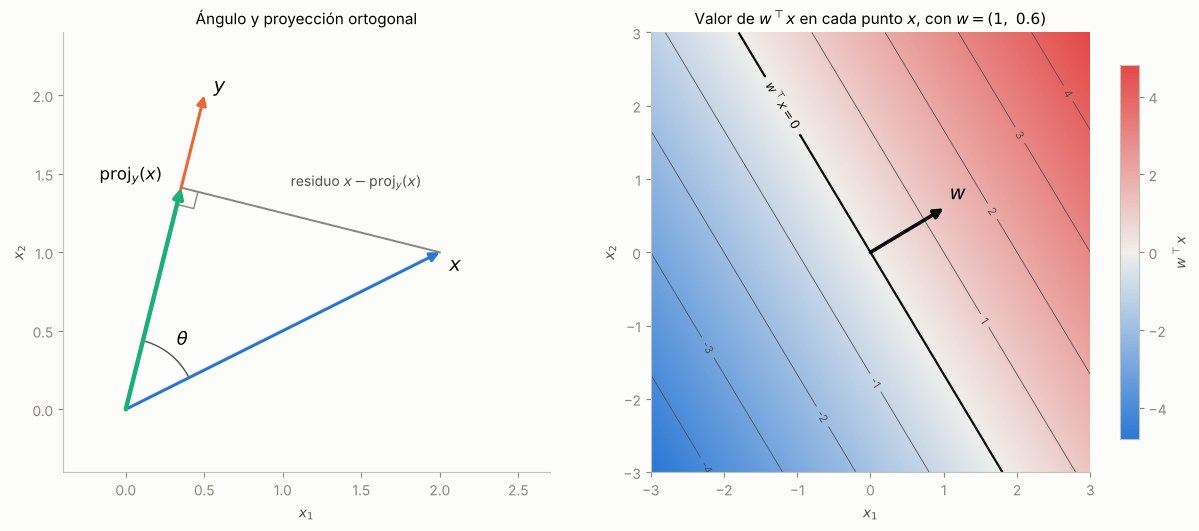

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2), layout="constrained")

# --- Panel izquierdo: ángulo y proyección ---------------------------------
p2 = proyeccion(x2, y2)
ax1.plot([x2[0], p2[0]], [x2[1], p2[1]], color=COL["tenue"], lw=1.4, zorder=2)      # residuo
flecha(ax1, x2, color=COL["azul"])
flecha(ax1, y2, color=COL["naranja"])
flecha(ax1, p2, color=COL["aqua"], lw=3.2, zorder=6)
u_y = y2 / norma(y2)                                   # marca de ángulo recto en el pie
r_u = (x2 - p2) / norma(x2 - p2)
s = 0.11
ax1.plot(*np.array([p2 + s * r_u, p2 + s * r_u - s * u_y, p2 - s * u_y]).T, color=COL["tenue"], lw=1)
ang_x, ang_y = np.arctan2(x2[1], x2[0]), np.arctan2(y2[1], y2[0])
tt = np.linspace(ang_x, ang_y, 60)
ax1.plot(0.45 * np.cos(tt), 0.45 * np.sin(tt), color=COL["tinta2"], lw=1)
mid = 0.5 * (ang_x + ang_y)
ax1.text(0.58 * np.cos(mid), 0.58 * np.sin(mid), r"$\theta$", fontsize=13, ha="center", va="center")
ax1.text(x2[0] + 0.06, x2[1] - 0.12, r"$x$", fontsize=14, color=COL["tinta"])
ax1.text(y2[0] + 0.06, y2[1] + 0.02, r"$y$", fontsize=14, color=COL["tinta"])
ax1.text(p2[0] - 0.12, p2[1] + 0.05, r"$\mathrm{proj}_y(x)$", fontsize=12, ha="right", color=COL["tinta"])
ax1.text(1.05, 1.42, r"residuo $x - \mathrm{proj}_y(x)$", fontsize=10, color=COL["tinta2"])
ax1.set_xlim(-0.4, 2.7); ax1.set_ylim(-0.4, 2.4); ax1.set_aspect("equal")
ax1.set_xlabel(r"$x_1$"); ax1.set_ylabel(r"$x_2$")
ax1.set_title("Ángulo y proyección ortogonal")

# --- Panel derecho: el campo w^T x ------------------------------------------
w = np.array([1.0, 0.6])
g = np.linspace(-3, 3, 301)
G1, G2 = np.meshgrid(g, g)
Z = w[0] * G1 + w[1] * G2
tope = np.abs(Z).max()
im = ax2.imshow(Z, extent=[-3, 3, -3, 3], origin="lower", cmap=DIVERGENTE, vmin=-tope, vmax=tope)
niveles = ax2.contour(G1, G2, Z, levels=[-4, -3, -2, -1, 1, 2, 3, 4], colors=COL["tinta2"], linewidths=0.6)
ax2.clabel(niveles, fmt="%d", fontsize=8)
cero = ax2.contour(G1, G2, Z, levels=[0], colors=COL["tinta"], linewidths=1.6)
ax2.clabel(cero, fmt={0: r"$w^\top x = 0$"}, fontsize=9, manual=[(-1.2, 2.0)])
flecha(ax2, w, color=COL["tinta"], lw=2.6)
ax2.text(w[0] + 0.08, w[1] + 0.12, r"$w$", fontsize=14)
ax2.set_xlabel(r"$x_1$"); ax2.set_ylabel(r"$x_2$")
ax2.set_title(r"Valor de $w^\top x$ en cada punto $x$, con $w = (1,\ 0.6)$")
fig.colorbar(im, ax=ax2, shrink=0.85, label=r"$w^\top x$")
plt.show()

### 1.8 Conexión con una neurona

Una neurona con pesos $w \in \mathbb{R}^n$ (por ahora sin sesgo) recibe una entrada $x \in \mathbb{R}^n$ y calcula $w^\top x$. Cauchy–Schwarz nos dice algo preciso sobre ella: entre todas las entradas con una norma fija $\|x\| = r$ (con $r > 0$), la respuesta $w^\top x$ nunca supera $\|w\|\, r$, y alcanza ese máximo exactamente cuando $x$ es un múltiplo positivo de $w$, es decir, cuando
$$
x = \frac{r}{\|w\|}\, w .
$$

Esto sugiere leer $w$ como una **plantilla**: la neurona responde mucho a las entradas que se parecen a $w$. Ojo con el estatus de cada afirmación: la desigualdad es un **teorema**; interpretar los pesos aprendidos de una red real como "plantillas" legibles es una **heurística de interpretación**, que a veces ayuda y a veces engaña.

**Para qué sirve más adelante.** El producto punto aparece en todas partes: la similitud coseno entre *embeddings* de palabras, el mecanismo de atención de los *transformers* (que compara vectores con productos punto), la potencia mecánica $P = F^\top v$ (fuerza por velocidad) en robótica, o el rendimiento $w^\top r$ de una cartera con pesos $w$ y rendimientos de los activos $r$ en finanzas.

## 2. Multiplicación matriz-vector como transformación lineal

### 2.1 La idea

Si una neurona es un producto punto, $m$ neuronas mirando la misma entrada son $m$ productos punto, y lo natural es apilar sus vectores de pesos como filas de una matriz. Pero una matriz tiene además una vida geométrica propia: **mueve el espacio entero**, enviando cada punto $x$ a otro punto $Ax$. En esta sección veremos las dos lecturas y qué significa exactamente que esa transformación sea "lineal".

### 2.2 Definición y dos lecturas

**Definición (producto matriz-vector).** Para $A \in \mathbb{R}^{m \times n}$ y $x \in \mathbb{R}^n$, el vector $Ax \in \mathbb{R}^m$ tiene componentes
$$
(Ax)_i = \sum_{j=1}^{n} A_{ij}\, x_j, \qquad i = 1, \dots, m .
$$

**Regla de dimensiones:** $(m \times n)\cdot(n \times 1) = (m \times 1)$. Las dimensiones interiores tienen que coincidir (el número de columnas de $A$ es el número de componentes de $x$) y "desaparecen"; las exteriores dan la forma del resultado. Esta es la regla que comprobaremos con `assert` una y otra vez.

La misma doble suma se puede agrupar de dos maneras, y cada una cuenta una historia distinta.

**Lectura por filas (la de las neuronas).** Si $a_i^\top \in \mathbb{R}^{1 \times n}$ denota la fila $i$ de $A$, entonces $(Ax)_i = a_i^\top x$. Cada componente del resultado es un producto punto: **$m$ neuronas, cada una comparando $x$ con su fila**.

**Lectura por columnas (la geométrica).** Si $c_j \in \mathbb{R}^m$ denota la columna $j$ de $A$, es decir, $A = \begin{pmatrix} c_1 & c_2 & \cdots & c_n \end{pmatrix}$, entonces
$$
Ax = x_1 c_1 + x_2 c_2 + \cdots + x_n c_n = \sum_{j=1}^{n} x_j\, c_j .
$$
El resultado es una **combinación lineal de las columnas**, y los coeficientes son las coordenadas de $x$. Consecuencia inmediata: el conjunto de todos los $Ax$ posibles (la *imagen* de $A$) es el subespacio generado por sus columnas.

¿Por qué las dos lecturas dan lo mismo? Porque calculan la misma suma finita sobre $i$ y $j$; solo cambia qué índice recorre el bucle exterior. En código se ve con claridad:

In [7]:
def matvec_filas(A, x):
    """Ax por filas: la componente i es el producto punto de la fila i de A con x."""
    m, n = A.shape
    assert x.shape == (n,), f"A es {m}x{n}, así que x debe tener forma ({n},), no {x.shape}"
    y = np.zeros(m)
    for i in range(m):                 # bucle exterior: filas (neuronas)
        y[i] = producto_punto(A[i, :], x)
    return y


def matvec_columnas(A, x):
    """Ax por columnas: combinación lineal de las columnas de A con coeficientes x_j."""
    m, n = A.shape
    assert x.shape == (n,), f"A es {m}x{n}, así que x debe tener forma ({n},), no {x.shape}"
    y = np.zeros(m)
    for j in range(n):                 # bucle exterior: columnas
        y += x[j] * A[:, j]
    return y


A = np.array([[1.0, 2.0, 0.0],
              [0.0, -1.0, 3.0]])
x = np.array([1.0, 1.0, 2.0])
print("por filas:   ", matvec_filas(A, x))
print("por columnas:", matvec_columnas(A, x))
print("A @ x:       ", A @ x)
comprobar_forma("A @ x", A @ x, (2,))

por filas:    [3. 5.]
por columnas: [3. 5.]
A @ x:        [3. 5.]
[ok] forma de A @ x = (2,)


Comprobación a mano con
$$
A = \begin{pmatrix} 1 & 2 & 0 \\ 0 & -1 & 3 \end{pmatrix} \in \mathbb{R}^{2\times 3},
\qquad
x = \begin{pmatrix} 1 \\ 1 \\ 2 \end{pmatrix} \in \mathbb{R}^3 .
$$
Por filas:
$$
Ax = \begin{pmatrix} 1\cdot 1 + 2\cdot 1 + 0 \cdot 2 \\ 0 \cdot 1 + (-1)\cdot 1 + 3 \cdot 2 \end{pmatrix} = \begin{pmatrix} 3 \\ 5 \end{pmatrix}.
$$
Por columnas:
$$
Ax = 1\begin{pmatrix} 1 \\ 0 \end{pmatrix} + 1 \begin{pmatrix} 2 \\ -1 \end{pmatrix} + 2 \begin{pmatrix} 0 \\ 3 \end{pmatrix} = \begin{pmatrix} 3 \\ 5 \end{pmatrix}.
$$

Ahora la verificación sistemática contra la librería, con matrices aleatorias de varias formas (incluidas no cuadradas), y lo que pasa cuando las dimensiones interiores no coinciden:

In [8]:
for (m, n) in [(1, 5), (4, 4), (7, 3), (50, 80)]:
    A_ = rng.standard_normal((m, n))
    x_ = rng.standard_normal(n)
    comprobar_forma(f"A_ @ x_ con A_ de {m}x{n}", A_ @ x_, (m,))
    comprobar_cercania("   filas = A_ @ x_   ", matvec_filas(A_, x_), A_ @ x_)
    comprobar_cercania("   columnas = A_ @ x_", matvec_columnas(A_, x_), A_ @ x_)

try:
    A @ np.ones(2)                      # A es 2x3: necesita un vector de R^3
except ValueError as error:
    print("Error de NumPy:", error)

[ok] forma de A_ @ x_ con A_ de 1x5 = (1,)
[ok]    filas = A_ @ x_     (error absoluto máximo = 0.0e+00)
[ok]    columnas = A_ @ x_  (error absoluto máximo = 0.0e+00)
[ok] forma de A_ @ x_ con A_ de 4x4 = (4,)
[ok]    filas = A_ @ x_     (error absoluto máximo = 2.2e-16)
[ok]    columnas = A_ @ x_  (error absoluto máximo = 2.2e-16)
[ok] forma de A_ @ x_ con A_ de 7x3 = (7,)
[ok]    filas = A_ @ x_     (error absoluto máximo = 1.1e-16)
[ok]    columnas = A_ @ x_  (error absoluto máximo = 1.1e-16)
[ok] forma de A_ @ x_ con A_ de 50x80 = (50,)
[ok]    filas = A_ @ x_     (error absoluto máximo = 1.1e-14)
[ok]    columnas = A_ @ x_  (error absoluto máximo = 1.1e-14)
Error de NumPy: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 3)


### 2.3 ¿Qué significa "lineal"?

**Definición (transformación lineal).** Una función $T : \mathbb{R}^n \to \mathbb{R}^m$ es lineal si para todo $u, v \in \mathbb{R}^n$ y todo $\alpha, \beta \in \mathbb{R}$
$$
T(\alpha u + \beta v) = \alpha\, T(u) + \beta\, T(v).
$$
En palabras: da igual combinar primero y transformar después, o transformar primero y combinar después.

**Teorema 1 (toda matriz define una transformación lineal).** Para cada $A \in \mathbb{R}^{m \times n}$, la función $T_A : \mathbb{R}^n \to \mathbb{R}^m$ dada por $T_A(x) = Ax$ es lineal.

*Demostración.* Componente a componente, para cada $i = 1, \dots, m$:
$$
\big(A(\alpha u + \beta v)\big)_i
= \sum_{j=1}^{n} A_{ij}(\alpha u_j + \beta v_j)
= \alpha \sum_{j=1}^{n} A_{ij} u_j + \beta \sum_{j=1}^{n} A_{ij} v_j
= \alpha (Au)_i + \beta (Av)_i . \qquad \blacksquare
$$

Lo sorprendente es que el recíproco también es cierto: **no hay transformaciones lineales entre espacios $\mathbb{R}^n$ que no sean matrices**. Para enunciarlo necesitamos la **base canónica**: $e_j \in \mathbb{R}^n$ es el vector con un $1$ en la posición $j$ y ceros en el resto, de modo que todo $x \in \mathbb{R}^n$ se escribe como
$$
x = \sum_{j=1}^{n} x_j\, e_j .
$$

**Teorema 2 (toda transformación lineal es una matriz).** Si $T : \mathbb{R}^n \to \mathbb{R}^m$ es lineal, existe una única matriz $A \in \mathbb{R}^{m \times n}$ tal que $T(x) = Ax$ para todo $x \in \mathbb{R}^n$, y sus columnas son las imágenes de la base canónica:
$$
A = \begin{pmatrix} T(e_1) & T(e_2) & \cdots & T(e_n) \end{pmatrix}.
$$

*Demostración.* *Existencia:* aplicando la linealidad repetidamente (formalmente, por inducción sobre el número de sumandos),
$$
T(x) = T\Big(\sum_{j=1}^{n} x_j e_j\Big) = \sum_{j=1}^{n} x_j\, T(e_j),
$$
que, por la lectura por columnas, es exactamente $Ax$ con $A$ definida como en el enunciado. *Unicidad:* si $Ax = Bx$ para todo $x$, tomando $x = e_j$ se obtiene que la columna $j$ de $A$ coincide con la columna $j$ de $B$, para cada $j$. $\blacksquare$

**La consecuencia clave para visualizar:** las columnas de $A$ son los lugares adonde van a parar $e_1, \dots, e_n$. Para entender una matriz $2\times 2$ basta mirar adónde envía $e_1$ y $e_2$; el resto del plano "se arrastra" con ellos, porque cada punto conserva sus coordenadas respecto a la nueva base.

**Geometría de la linealidad.** Una recta que pasa por $p \in \mathbb{R}^n$ con dirección $d \in \mathbb{R}^n$ es el conjunto de puntos $p + t d$, con $t \in \mathbb{R}$. Su imagen es
$$
A(p + t d) = Ap + t\, Ad ,
$$
que es otra recta (pasa por $Ap$ con dirección $Ad$), o un solo punto si $Ad = 0$. Además: rectas paralelas (misma $d$) van a rectas paralelas (misma $Ad$); puntos equiespaciados (valores de $t$ equiespaciados) siguen equiespaciados; y el origen queda fijo, porque $A0 = 0$. Por eso una cuadrícula se transforma en una cuadrícula de paralelogramos.

### 2.4 Verificación numérica

Tres experimentos: (a) la linealidad de $x \mapsto Ax$ con datos aleatorios; (b) una función que **no** es lineal falla la misma prueba; (c) el teorema 2 en acción: reconstruimos la matriz de una "caja negra" lineal evaluándola solo en $e_1$ y $e_2$. La caja negra rota los puntos $30^\circ$ usando números complejos (multiplicar por $e^{i\varphi}$ rota un ángulo $\varphi$), sin ninguna matriz a la vista.

In [9]:
# (a) Linealidad de x -> Ax con datos aleatorios.
A = rng.standard_normal((3, 4))
u, v = rng.standard_normal(4), rng.standard_normal(4)
alfa, beta = rng.standard_normal(2)
comprobar_cercania("A(alfa u + beta v) = alfa Au + beta Av",
                   A @ (alfa * u + beta * v), alfa * (A @ u) + beta * (A @ v))

# (b) Elevar al cuadrado componente a componente NO es lineal: la diferencia no es cero.
g = lambda z: z ** 2
print("(b) g(alfa u + beta v) - (alfa g(u) + beta g(v)) =", g(alfa * u + beta * v) - (alfa * g(u) + beta * g(v)))


# (c) Reconstruir la matriz de una caja negra lineal: columnas = T(e_j).
def rotar_30(p):
    """Rota p en R^2 30 grados, usando multiplicación de números complejos."""
    z = complex(p[0], p[1]) * np.exp(1j * np.radians(30))
    return np.array([z.real, z.imag])


e1, e2 = np.array([1.0, 0.0]), np.array([0.0, 1.0])
R_reconstruida = np.column_stack([rotar_30(e1), rotar_30(e2)])
phi = np.radians(30)
R_teorica = np.array([[np.cos(phi), -np.sin(phi)],
                      [np.sin(phi),  np.cos(phi)]])
print("(c) matriz reconstruida a partir de T(e1) y T(e2):\n", R_reconstruida)
comprobar_cercania("matriz reconstruida = matriz de rotación teórica", R_reconstruida, R_teorica)
p = rng.standard_normal(2)
comprobar_cercania("T(p) = R p para un p cualquiera", rotar_30(p), R_reconstruida @ p)

[ok] A(alfa u + beta v) = alfa Au + beta Av  (error absoluto máximo = 3.3e-16)
(b) g(alfa u + beta v) - (alfa g(u) + beta g(v)) = [ 1.8106 -0.0319  0.2218 -1.2848]
(c) matriz reconstruida a partir de T(e1) y T(e2):
 [[ 0.866 -0.5  ]
 [ 0.5    0.866]]
[ok] matriz reconstruida = matriz de rotación teórica  (error absoluto máximo = 0.0e+00)
[ok] T(p) = R p para un p cualquiera  (error absoluto máximo = 3.5e-18)


### 2.5 Visualización: "la misma receta con ingredientes nuevos"

Para dibujar una transformación aplicamos $A$ a muchos puntos a la vez. Si guardamos $N$ puntos de $\mathbb{R}^2$ como **filas** de una matriz $P \in \mathbb{R}^{N\times 2}$ (fila $k$: $p_k^\top$), entonces la fila $k$ de $PA^\top$ es, usando $(AB)^\top = B^\top A^\top$,
$$
p_k^\top A^\top = (A p_k)^\top .
$$
Es decir, `P @ A.T` aplica $A$ a todos los puntos de una vez. (Esta convención de "puntos en filas" volverá en la sección 3.5.)

Tomemos
$$
A = \begin{pmatrix} 2 & -1 \\ 1 & 1 \end{pmatrix},
\qquad
x = \begin{pmatrix} 1.5 \\ 1 \end{pmatrix} = 1.5\, e_1 + 1\, e_2 .
$$
La lectura por columnas dice que $Ax = 1.5\, c_1 + 1\, c_2$, con $c_1 = Ae_1 = (2, 1)^\top$ y $c_2 = Ae_2 = (-1, 1)^\top$, así que
$$
Ax = 1.5\begin{pmatrix} 2 \\ 1 \end{pmatrix} + 1\begin{pmatrix} -1 \\ 1 \end{pmatrix} = \begin{pmatrix} 3 \\ 1.5 \end{pmatrix} + \begin{pmatrix} -1 \\ 1 \end{pmatrix} = \begin{pmatrix} 2 \\ 2.5 \end{pmatrix}.
$$
**Las coordenadas de $x$ (la receta) no cambian; lo que cambia son los vectores base (los ingredientes).** A la izquierda construimos $x$ con $e_1, e_2$; a la derecha construimos $Ax$ con $c_1, c_2$, con los mismos coeficientes. Las rectas azules son paralelas a $e_1$ y las naranjas a $e_2$; a la derecha vemos sus imágenes.

[ok] A x = 1.5 c1 + 1 c2  (error absoluto máximo = 0.0e+00)


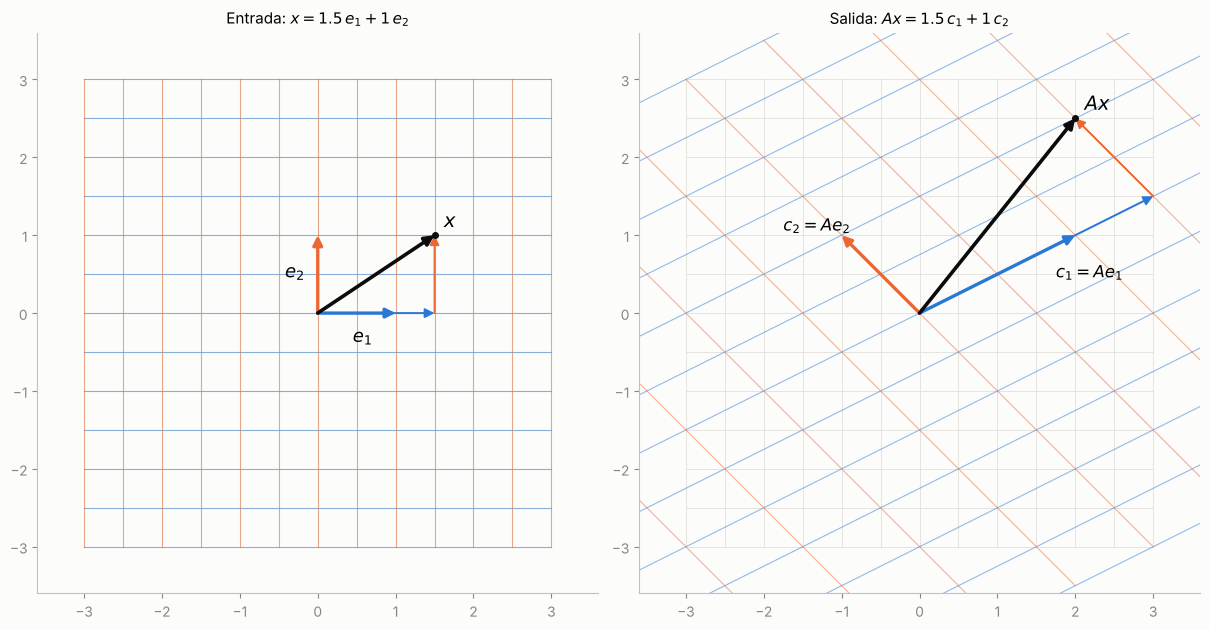

In [10]:
def lineal(A):
    """Devuelve la función P -> P A^T, que aplica x -> Ax a cada fila de P."""
    return lambda P: P @ A.T


def cuadricula(lim=3.0, paso=0.5, n_puntos=300):
    """Rectas horizontales (paralelas a e1) y verticales (paralelas a e2), como polilíneas (n_puntos, 2)."""
    t = np.linspace(-lim, lim, n_puntos)
    valores = np.arange(-lim, lim + 1e-9, paso)
    horizontales = [np.column_stack([t, np.full_like(t, c)]) for c in valores]
    verticales = [np.column_stack([np.full_like(t, c), t]) for c in valores]
    return horizontales, verticales


def contorno_cuadrado(n=200):
    """Borde del cuadrado unidad [0,1]^2 muestreado densamente (sirve también para funciones no lineales)."""
    s = np.linspace(0.0, 1.0, n)
    uno, cero = np.ones_like(s), np.zeros_like(s)
    return np.vstack([np.column_stack([s, cero]), np.column_stack([uno, s]),
                      np.column_stack([1 - s, uno]), np.column_stack([cero, 1 - s])])


def dibujar_transformacion(ax, f, titulo="", lim=3.0, ver=3.5, cuadrado=True, circulo=True, flechas=True):
    """Dibuja cómo f: R^2 -> R^2 (que actúa sobre las filas de una matriz) deforma el plano.

    Gris claro: cuadrícula original. Azul / naranja: imágenes de las rectas paralelas a e1 / e2.
    Aqua: imagen del cuadrado unidad. Gris oscuro: imagen de la circunferencia unidad.
    Flechas: de f(0) a f(e1) (azul) y a f(e2) (naranja); si f es lineal, son las columnas de A.
    """
    horizontales, verticales = cuadricula(lim)
    for linea in horizontales + verticales:
        ax.plot(linea[:, 0], linea[:, 1], color=COL["rejilla"], lw=0.6, zorder=0)
    for familia, color in [(horizontales, COL["azul"]), (verticales, COL["naranja"])]:
        for linea in familia:
            L = f(linea)
            ax.plot(L[:, 0], L[:, 1], color=color, lw=0.8, alpha=0.5, zorder=1)
    if cuadrado:
        C = f(contorno_cuadrado())
        ax.fill(C[:, 0], C[:, 1], color=COL["aqua"], alpha=0.35, lw=0, zorder=2)
    if circulo:
        th = np.linspace(0, 2 * np.pi, 400)
        circ = f(np.column_stack([np.cos(th), np.sin(th)]))
        ax.plot(circ[:, 0], circ[:, 1], color=COL["tinta2"], lw=1.4, zorder=3)
    if flechas:
        origen = f(np.zeros((1, 2)))[0]
        flecha(ax, f(np.array([[1.0, 0.0]]))[0], origen, color=COL["azul"], lw=2.4)
        flecha(ax, f(np.array([[0.0, 1.0]]))[0], origen, color=COL["naranja"], lw=2.4)
    ax.set_xlim(-ver, ver); ax.set_ylim(-ver, ver); ax.set_aspect("equal")
    ax.set_title(titulo)


A = np.array([[2.0, -1.0],
              [1.0, 1.0]])
x = np.array([1.5, 1.0])
c1, c2 = A[:, 0], A[:, 1]
comprobar_cercania("A x = 1.5 c1 + 1 c2", A @ x, x[0] * c1 + x[1] * c2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), layout="constrained")
identidad = lambda P: P
dibujar_transformacion(ax1, identidad, r"Entrada: $x = 1.5\,e_1 + 1\,e_2$", ver=3.6, cuadrado=False, circulo=False)
dibujar_transformacion(ax2, lineal(A), r"Salida: $Ax = 1.5\,c_1 + 1\,c_2$", ver=3.6, cuadrado=False, circulo=False)
for ax, b1, b2, nombre in [(ax1, e1, e2, "x"), (ax2, c1, c2, "Ax")]:
    paso1 = x[0] * b1
    flecha(ax, paso1, color=COL["azul"], lw=1.4, zorder=4)                     # 1.5 * (primer vector base)
    flecha(ax, paso1 + x[1] * b2, paso1, color=COL["naranja"], lw=1.4, zorder=4)  # + 1 * (segundo)
    destino = paso1 + x[1] * b2
    flecha(ax, destino, color=COL["tinta"], lw=2.6, zorder=6)
    ax.plot(*destino, "o", color=COL["tinta"], ms=4, zorder=7)
    ax.text(destino[0] + 0.12, destino[1] + 0.1, f"${nombre}$", fontsize=14, zorder=8)
ax1.text(0.45, -0.38, r"$e_1$", fontsize=13); ax1.text(-0.42, 0.45, r"$e_2$", fontsize=13)
ax2.text(1.75, 0.45, r"$c_1 = Ae_1$", fontsize=12); ax2.text(-1.75, 1.05, r"$c_2 = Ae_2$", fontsize=12)
plt.show()

### 2.6 Galería de transformaciones y el determinante

Ahora aplicamos la misma herramienta a seis matrices con personalidades distintas. En cada panel: la cuadrícula original en gris claro; en azul y naranja, las imágenes de las rectas paralelas a $e_1$ y a $e_2$; las flechas son $Ae_1$ (azul) y $Ae_2$ (naranja), es decir, **las columnas de $A$**; en aqua, la imagen del cuadrado unidad $[0,1]^2$; en gris oscuro, la imagen de la circunferencia unidad.

En el título de cada panel aparece el **determinante**, que para $A \in \mathbb{R}^{2\times 2}$ es
$$
\det A = A_{11}A_{22} - A_{12}A_{21}.
$$

**Teorema (el determinante como factor de área).** Si $A \in \mathbb{R}^{2\times 2}$ y $S \subset \mathbb{R}^2$ es una región con área, entonces el área de su imagen $A(S)$ es $|\det A|$ veces el área de $S$. El signo de $\det A$ indica si $A$ conserva la orientación ($\det A > 0$: girar de $Ae_1$ a $Ae_2$ sigue siendo antihorario) o la invierte ($\det A < 0$, como un espejo). Si $\det A = 0$, el plano se aplasta sobre una recta o un punto y la transformación no se puede deshacer.

*Demostración para el cuadrado unidad.* Su imagen es el paralelogramo de lados $c_1 = (A_{11}, A_{21})^\top$ y $c_2 = (A_{12}, A_{22})^\top$, cuya área es base por altura, $\|c_1\|\,\|c_2\|\sin\theta$, donde $\theta$ es el ángulo entre $c_1$ y $c_2$. Usando $\sin^2\theta = 1 - \cos^2\theta$ y la fórmula del coseno de la sección 1.4:
$$
\begin{aligned}
\text{área}^2 &= \|c_1\|^2\|c_2\|^2\,(1 - \cos^2\theta) = \|c_1\|^2\|c_2\|^2 - (c_1^\top c_2)^2 \\
&= (A_{11}^2 + A_{21}^2)(A_{12}^2 + A_{22}^2) - (A_{11}A_{12} + A_{21}A_{22})^2 \\
&= A_{11}^2A_{22}^2 + A_{21}^2A_{12}^2 - 2A_{11}A_{12}A_{21}A_{22} \\
&= (A_{11}A_{22} - A_{12}A_{21})^2 = (\det A)^2 . \qquad \blacksquare
\end{aligned}
$$
(En la tercera línea, los términos $A_{11}^2A_{12}^2$ y $A_{21}^2A_{22}^2$ aparecen en los dos productos y se cancelan.) **El caso de una región general lo enunciamos sin demostración:** la prueba usa el teorema de cambio de variables del cálculo multivariado, y la interpretación del signo requiere formalizar la noción de orientación.

También observarás que la circunferencia se convierte en una **elipse** cuando $A$ es invertible. Esto es un teorema que demostraremos cuando veamos la descomposición en valores singulares (SVD); de momento, tómalo como una observación.

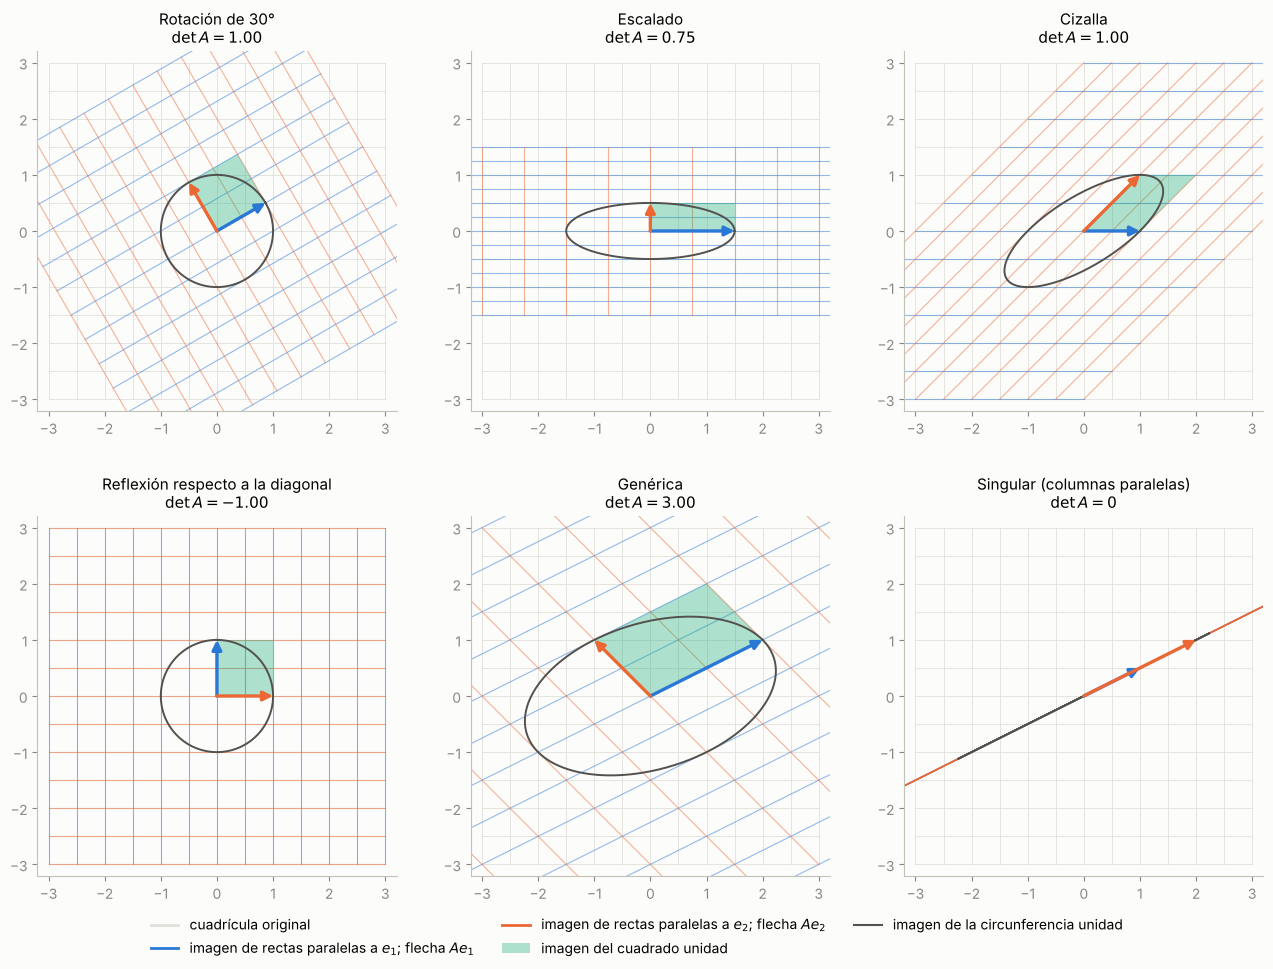

In [11]:
phi = np.radians(30)
galeria = {
    "Rotación de 30°": np.array([[np.cos(phi), -np.sin(phi)], [np.sin(phi), np.cos(phi)]]),
    "Escalado": np.array([[1.5, 0.0], [0.0, 0.5]]),
    "Cizalla": np.array([[1.0, 1.0], [0.0, 1.0]]),
    "Reflexión respecto a la diagonal": np.array([[0.0, 1.0], [1.0, 0.0]]),
    "Genérica": np.array([[2.0, -1.0], [1.0, 1.0]]),
    "Singular (columnas paralelas)": np.array([[1.0, 2.0], [0.5, 1.0]]),
}


def texto_det(M):
    d = np.linalg.det(M)
    return "0" if abs(d) < 1e-12 else f"{d:.2f}"


fig, axes = plt.subplots(2, 3, figsize=(13, 9.6), layout="constrained")
for ax, (nombre, M) in zip(axes.flat, galeria.items()):
    dibujar_transformacion(ax, lineal(M), nombre + "\n" + rf"$\det A = {texto_det(M)}$", ver=3.2)

leyenda = [
    Line2D([], [], color=COL["rejilla"], lw=2, label="cuadrícula original"),
    Line2D([], [], color=COL["azul"], lw=2, label=r"imagen de rectas paralelas a $e_1$; flecha $Ae_1$"),
    Line2D([], [], color=COL["naranja"], lw=2, label=r"imagen de rectas paralelas a $e_2$; flecha $Ae_2$"),
    Patch(facecolor=COL["aqua"], alpha=0.35, label="imagen del cuadrado unidad"),
    Line2D([], [], color=COL["tinta2"], lw=1.5, label="imagen de la circunferencia unidad"),
]
fig.legend(handles=leyenda, loc="outside lower center", ncol=3)
fig.get_layout_engine().set(hspace=0.08)
plt.show()

**Verificación numérica del factor de área.** Calculamos el área con signo de un polígono con la *fórmula del área de Gauss* (conocida como fórmula del "cordón de zapato"; se deduce del teorema de Green y aquí la usamos sin demostrarla): para un polígono con vértices $(u_k, v_k)$, $k = 1, \dots, N$, recorridos en orden y cerrando con $(u_{N+1}, v_{N+1}) = (u_1, v_1)$,
$$
\text{área con signo} = \frac{1}{2}\sum_{k=1}^{N} \big(u_k v_{k+1} - u_{k+1} v_k\big).
$$
Es positiva si el recorrido es antihorario. Comprobamos que el cuadrado unidad (área $1$, recorrido antihorario) se transforma en un paralelogramo de área con signo $\det A$, y que el círculo unidad (área $\pi$, aproximado por un polígono de 4000 lados) pasa a tener área $\pi\,|\det A|$.

In [12]:
def area_poligono(V):
    """Área con signo de un polígono de vértices V (N, 2), en orden (fórmula de Gauss)."""
    u, v = V[:, 0], V[:, 1]
    return 0.5 * np.sum(u * np.roll(v, -1) - np.roll(u, -1) * v)


cuadrado = np.array([[0.0, 0.0], [1.0, 0.0], [1.0, 1.0], [0.0, 1.0]])      # antihorario
th = np.linspace(0, 2 * np.pi, 4000, endpoint=False)
circulo = np.column_stack([np.cos(th), np.sin(th)])

print(f"{'matriz':<34}{'det A':>8}{'área(A·cuadrado)':>19}{'área(A·círculo)/π':>20}")
for nombre, M in galeria.items():
    area_c = area_poligono(cuadrado @ M.T)
    area_o = area_poligono(circulo @ M.T) / np.pi
    print(f"{nombre:<34}{np.linalg.det(M):>8.3f}{area_c:>19.3f}{area_o:>20.4f}")
    assert abs(area_c - np.linalg.det(M)) < 1e-12, nombre
print("[ok] en las seis matrices, el área con signo del cuadrado transformado coincide con det A")

matriz                               det A   área(A·cuadrado)   área(A·círculo)/π
Rotación de 30°                      1.000              1.000              1.0000
Escalado                             0.750              0.750              0.7500
Cizalla                              1.000              1.000              1.0000
Reflexión respecto a la diagonal    -1.000             -1.000             -1.0000
Genérica                             3.000              3.000              3.0000
Singular (columnas paralelas)        0.000              0.000              0.0000
[ok] en las seis matrices, el área con signo del cuadrado transformado coincide con det A


El área del círculo transformado coincide con $\pi\,\det A$ hasta el cuarto decimal: la pequeña diferencia es el error de aproximar el círculo por un polígono, no un error de la teoría. Fíjate también en que la reflexión da área con signo **negativa**: invierte la orientación.

**Para qué sirve más adelante.** Las rotaciones ($\det A = 1$, y además conservan longitudes y ángulos) son el lenguaje de la orientación de un robot o de una cámara; el determinante es el factor que aparece en el cambio de variables de una densidad de probabilidad (por ejemplo, en los *normalizing flows*); y una matriz singular es una pérdida irrecuperable de información, idea que volverá en 4.5.

## 3. La capa $y = Wx + b$

### 3.1 La idea

Una capa densa con $n$ entradas y $m$ salidas (o $m$ neuronas) calcula
$$
y = Wx + b,
\qquad x \in \mathbb{R}^n,\quad W \in \mathbb{R}^{m \times n},\quad b \in \mathbb{R}^m,\quad y \in \mathbb{R}^m .
$$
$W$ es la **matriz de pesos** y $b$ el **vector de sesgos** (*bias*). Con lo que ya sabemos, hay dos maneras de leerla:

- **Por filas (neuronas).** Si $w_i^\top$ es la fila $i$ de $W$, la neurona $i$ calcula $y_i = w_i^\top x + b_i$: un producto punto (¿cuánto se parece $x$ a la plantilla $w_i$?) más un umbral $b_i$.
- **Geométrica.** Primero la transformación lineal $x \mapsto Wx$ deforma el espacio (sección 2) y luego el sumando $b$ lo **traslada** rígidamente.

¿Para qué sirve $b$? Sin él, el origen siempre va al origen, y la frontera de cada neurona, $\lbrace x : w_i^\top x = 0 \rbrace$, está obligada a pasar por el origen (como en la figura de 1.7). El sesgo elimina esa restricción.

### 3.2 Lineal frente a afín

**Definición (función afín).** $f : \mathbb{R}^n \to \mathbb{R}^m$ es afín si existen $W \in \mathbb{R}^{m\times n}$ y $b \in \mathbb{R}^m$ tales que $f(x) = Wx + b$ para todo $x \in \mathbb{R}^n$.

**Proposición.** Si $b \neq 0$, la función $f(x) = Wx + b$ no es lineal.

*Demostración.* Toda transformación lineal $T$ cumple $T(0) = 0$, porque, usando la definición con $\alpha = \beta = 0$, $T(0) = T(0 \cdot 0 + 0 \cdot 0) = 0 \cdot T(0) + 0 \cdot T(0) = 0$. Pero $f(0) = W0 + b = b \neq 0$. $\blacksquare$

Más precisamente, la aditividad falla exactamente por $b$:
$$
f(u + v) = W(u+v) + b = (Wu + b) + (Wv + b) - b = f(u) + f(v) - b .
$$
Lo que sí conserva una función afín son las **combinaciones afines**, las que tienen coeficientes que suman $1$: para todo $u, v \in \mathbb{R}^n$ y todo $\lambda \in \mathbb{R}$,
$$
f\big(\lambda u + (1-\lambda) v\big) = \lambda\, Wu + (1 - \lambda)\, Wv + \underbrace{\lambda b + (1-\lambda) b}_{=\,b} = \lambda f(u) + (1 - \lambda) f(v).
$$
Como la recta que pasa por $u$ y $v$ es justamente el conjunto de las combinaciones afines $\lambda u + (1-\lambda) v$, las funciones afines siguen enviando rectas a rectas y paralelas a paralelas; lo único que pierden es el origen fijo.

**Nota de vocabulario.** En la jerga de redes neuronales se suele llamar "capa lineal" a lo que en matemáticas es una función afín (por ejemplo, `torch.nn.Linear` incluye el sesgo). No es grave, pero conviene saber que, en sentido estricto, solo es lineal si $b = 0$.

### 3.3 Coordenadas homogéneas: afín en $n$ dimensiones es lineal en $n+1$

Hay un truco que convierte cualquier función afín en una lineal, añadiendo una coordenada constante igual a $1$:
$$
\begin{pmatrix} y \\ 1 \end{pmatrix}
= \underbrace{\begin{pmatrix} W & b \\ 0^\top & 1 \end{pmatrix}}_{\widetilde{W} \,\in\, \mathbb{R}^{(m+1)\times(n+1)}}
\begin{pmatrix} x \\ 1 \end{pmatrix},
$$
donde $0 \in \mathbb{R}^n$ es el vector nulo. Haciendo el producto por bloques, el bloque superior da $Wx + b\cdot 1 = y$ y el inferior da $0^\top x + 1 \cdot 1 = 1$.

**Para qué sirve en robótica.** Un movimiento rígido del espacio, rotar con una matriz de rotación $R \in \mathbb{R}^{3\times3}$ y trasladar con $t \in \mathbb{R}^3$, es la función afín $p \mapsto Rp + t$: exactamente la misma estructura que una capa. En robótica se escribe como una matriz homogénea de $4 \times 4$, y encadenar los sistemas de referencia de los eslabones de un brazo es multiplicar esas matrices. Lo usaremos en la sección 4 para dar una segunda demostración del colapso.

### 3.4 Ejemplo numérico, a mano

Tomemos una capa con $n = 3$ entradas y $m = 2$ neuronas:
$$
W = \begin{pmatrix} 1 & -1 & 2 \\ 0 & 3 & -1 \end{pmatrix} \in \mathbb{R}^{2\times 3},
\qquad
b = \begin{pmatrix} 1 \\ -2 \end{pmatrix} \in \mathbb{R}^{2},
\qquad
x = \begin{pmatrix} 2 \\ 1 \\ -1 \end{pmatrix} \in \mathbb{R}^{3} .
$$
Dimensiones: $(2 \times 3)\cdot(3 \times 1) = (2 \times 1)$, y sumar $b$, de tamaño $2 \times 1$, mantiene la forma. Calculamos:
$$
Wx = \begin{pmatrix} 1\cdot 2 + (-1)\cdot 1 + 2\cdot(-1) \\ 0\cdot 2 + 3\cdot 1 + (-1)\cdot(-1) \end{pmatrix} = \begin{pmatrix} -1 \\ 4 \end{pmatrix},
\qquad
y = Wx + b = \begin{pmatrix} -1 + 1 \\ 4 - 2 \end{pmatrix} = \begin{pmatrix} 0 \\ 2 \end{pmatrix}.
$$
Fíjate en que la neurona 1 da exactamente $0$: este $x$ está justo sobre su frontera de decisión. En 3.6 veremos qué significa eso geométricamente.

In [13]:
def capa_desde_cero(W, b, x):
    """y = W x + b con bucles explícitos: la neurona i calcula w_i^T x + b_i."""
    m, n = W.shape
    assert b.shape == (m,), f"b debe tener forma ({m},), tiene {b.shape}"
    assert x.shape == (n,), f"x debe tener forma ({n},), tiene {x.shape}"
    y = np.zeros(m)
    for i in range(m):
        y[i] = producto_punto(W[i, :], x) + b[i]
    return y


W_ej = np.array([[1.0, -1.0, 2.0],
                 [0.0, 3.0, -1.0]])
b_ej = np.array([1.0, -2.0])
x_ej = np.array([2.0, 1.0, -1.0])

y_ej = capa_desde_cero(W_ej, b_ej, x_ej)
print("desde cero:", y_ej)
print("W @ x + b: ", W_ej @ x_ej + b_ej)
comprobar_forma("y", y_ej, (2,))
comprobar_cercania("desde cero = librería", y_ej, W_ej @ x_ej + b_ej)
comprobar_cercania("coincide con el cálculo a mano", y_ej, [0.0, 2.0])

# Coordenadas homogéneas: la misma capa como UNA matriz lineal de 3x4.
W_tilde = np.block([[W_ej, b_ej[:, None]],
                    [np.zeros((1, 3)), np.ones((1, 1))]])
comprobar_forma("W_tilde", W_tilde, (3, 4))
y_hom = W_tilde @ np.append(x_ej, 1.0)
print("en homogéneas:", y_hom, " (la última componente siempre es 1)")
comprobar_cercania("homogéneas = afín", y_hom[:2], y_ej)

# f es afín pero no lineal.
f = lambda z: W_ej @ z + b_ej
u, v = rng.standard_normal(3), rng.standard_normal(3)
print("f(0) =", f(np.zeros(3)), " (si f fuera lineal, sería el vector nulo)")
comprobar_cercania("f(u+v) = f(u) + f(v) - b", f(u + v), f(u) + f(v) - b_ej)
lam = 2.7     # cualquier lambda real, incluso fuera de [0, 1]
comprobar_cercania("f conserva combinaciones afines", f(lam * u + (1 - lam) * v), lam * f(u) + (1 - lam) * f(v))

desde cero: [0. 2.]
W @ x + b:  [0. 2.]
[ok] forma de y = (2,)
[ok] desde cero = librería  (error absoluto máximo = 0.0e+00)
[ok] coincide con el cálculo a mano  (error absoluto máximo = 0.0e+00)
[ok] forma de W_tilde = (3, 4)
en homogéneas: [0. 2. 1.]  (la última componente siempre es 1)
[ok] homogéneas = afín  (error absoluto máximo = 0.0e+00)
f(0) = [ 1. -2.]  (si f fuera lineal, sería el vector nulo)
[ok] f(u+v) = f(u) + f(v) - b  (error absoluto máximo = 8.9e-16)
[ok] f conserva combinaciones afines  (error absoluto máximo = 1.8e-15)


### 3.5 Muchos ejemplos a la vez: lotes y *broadcasting*

En la práctica no pasamos un ejemplo por la red, sino un **lote** (*batch*) de $N$ ejemplos a la vez. La convención de NumPy y PyTorch es guardarlos como **filas** de una matriz $X \in \mathbb{R}^{N\times n}$, cuya fila $k$ es $x^{(k)\top}$, el ejemplo $k$-ésimo ($k = 1, \dots, N$). Queremos la matriz $Y \in \mathbb{R}^{N\times m}$ cuya fila $k$ sea la salida del ejemplo $k$. Transponiendo con $(AB)^\top = B^\top A^\top$:
$$
\big(Wx^{(k)} + b\big)^\top = x^{(k)\top} W^\top + b^\top
\quad\Longrightarrow\quad
Y = X W^\top + \mathbf{1}_N\, b^\top ,
$$
donde $\mathbf{1}_N \in \mathbb{R}^N$ es el vector de unos, de modo que $\mathbf{1}_N b^\top \in \mathbb{R}^{N\times m}$ es la matriz que repite $b^\top$ en cada fila.

Dimensiones: $(N \times n)\cdot(n \times m) = (N\times m)$. El término $\mathbf{1}_N b^\top$ es lo que NumPy hace **implícitamente** al escribir `X @ W.T + b` con `b.shape == (m,)`: el *broadcasting* "estira" `b` hasta la forma `(N, m)`. Esta transposición es la razón por la que `torch.nn.Linear` guarda sus pesos con forma `(out_features, in_features)`, es decir $(m, n)$, y calcula $XW^\top + b$. Que las filas sean los ejemplos es una **convención** de software, no un hecho matemático; lo importante es ser consistente.

In [14]:
N = 5
X_lote = rng.standard_normal((N, 3))
Y_lote = X_lote @ W_ej.T + b_ej         # broadcasting: b_ej (2,) se suma a cada fila de (5, 2)
comprobar_forma("X_lote", X_lote, (N, 3))
comprobar_forma("Y_lote", Y_lote, (N, 2))

# Igual que aplicar la capa ejemplo a ejemplo (desde cero)...
Y_bucle = np.array([capa_desde_cero(W_ej, b_ej, X_lote[k]) for k in range(N)])
comprobar_cercania("lote vectorizado = bucle por ejemplos", Y_lote, Y_bucle)

# ...e igual que la fórmula explícita con 1_N b^T, sin broadcasting:
Y_explicita = X_lote @ W_ej.T + np.ones((N, 1)) @ b_ej[None, :]
comprobar_cercania("broadcasting = 1_N b^T explícito", Y_lote, Y_explicita)

[ok] forma de X_lote = (5, 3)
[ok] forma de Y_lote = (5, 2)
[ok] lote vectorizado = bucle por ejemplos  (error absoluto máximo = 0.0e+00)
[ok] broadcasting = 1_N b^T explícito  (error absoluto máximo = 0.0e+00)


**Una trampa clásica del broadcasting.** El broadcasting es cómodo, pero puede convertir un error de forma en un resultado **silenciosamente incorrecto**. Si por descuido guardamos el sesgo como columna, con forma `(m, 1)` en lugar de `(m,)`, NumPy no protesta. Alinea las formas por la derecha: `(2,)` se trata como `(1, 2)`, y al combinarla con `(2, 1)` ambas se estiran hasta `(2, 2)`, con entrada $(i, j)$ igual a $(Wx)_j + b_i$. El resultado es una matriz que no significa nada. Por eso comprobamos formas explícitamente.

In [15]:
b_columna = b_ej.reshape(2, 1)          # mismo contenido, forma (2, 1)
y_mal = W_ej @ x_ej + b_columna         # (2,) + (2, 1)  ->  (2, 2)  ¡sin ningún error!
print("forma obtenida:", y_mal.shape)
print(y_mal)
try:
    comprobar_forma("y_mal", y_mal, (2,))
except AssertionError as error:
    print("La comprobación de forma lo detecta:", error)

forma obtenida: (2, 2)
[[ 0.  5.]
 [-3.  2.]]
La comprobación de forma lo detecta: y_mal: forma (2, 2), se esperaba (2,)


### 3.6 Geometría de cada neurona: hiperplanos y distancia con signo

Para la neurona $i$, el conjunto donde su salida vale cero,
$$
H_i = \lbrace x \in \mathbb{R}^n : w_i^\top x + b_i = 0 \rbrace ,
$$
es un **hiperplano** (una recta en $\mathbb{R}^2$, un plano en $\mathbb{R}^3$) con **vector normal** $w_i$; suponemos $w_i \neq 0$. Por la sección 1.7 ya sabíamos que los conjuntos de nivel de $x \mapsto w_i^\top x$ son perpendiculares a $w_i$; el sesgo solo elige cuál de ellos es el nivel cero. Llamemos $\hat{w}_i$ a la normal unitaria,
$$
\hat{w}_i = \frac{w_i}{\|w_i\|}.
$$

**Proposición (la salida de una neurona es una distancia con signo, escalada).** La distancia con signo de $x \in \mathbb{R}^n$ a $H_i$, positiva en el lado hacia el que apunta $w_i$, es
$$
d_i(x) = \frac{w_i^\top x + b_i}{\|w_i\|},
\qquad\text{y por tanto}\qquad
y_i = \|w_i\|\; d_i(x).
$$

*Demostración.* Sea $x_0 \in H_i$ un punto cualquiera del hiperplano, de modo que $w_i^\top x_0 = -b_i$. Al ir de $x_0$ a $x$, la componente del desplazamiento $x - x_0$ paralela al hiperplano no nos acerca ni nos aleja de él; solo cuenta la componente en la dirección normal, que por la sección 1.5 es $\hat{w}_i^\top (x - x_0)$. Así,
$$
d_i(x) = \hat{w}_i^\top (x - x_0) = \frac{w_i^\top x - w_i^\top x_0}{\|w_i\|} = \frac{w_i^\top x + b_i}{\|w_i\|}.
$$
El resultado no depende del $x_0$ elegido, como debe ser. $\blacksquare$

**Interpretación.** Cada neurona parte el espacio en dos semiespacios, y su salida dice de qué lado está $x$ y a qué distancia (multiplicada por $\|w_i\|$). En el ejemplo de 3.4, $y_1 = 0$ significa que $x$ está sobre $H_1$.

**Verificación numérica.** Movemos $x$ una distancia $d_1(x)$ en la dirección $-\hat{w}_1$ y comprobamos que caemos exactamente sobre $H_1$; luego comprobamos que ningún otro punto de $H_1$, entre 10 000 elegidos al azar, está más cerca de $x$.

In [16]:
w1, b1 = W_ej[0], b_ej[0]
x = rng.standard_normal(3)
d = (w1 @ x + b1) / np.linalg.norm(w1)
x_H = x - d * w1 / np.linalg.norm(w1)          # pie de la perpendicular
print(f"d_1(x) = {d:.4f}")
comprobar_cercania("x_H está en H_1 (w1^T x_H + b1 = 0)", w1 @ x_H + b1, 0.0)
comprobar_cercania("||x - x_H|| = |d_1(x)|", np.linalg.norm(x - x_H), abs(d))

# Puntos aleatorios de H_1: tomamos z al azar y lo proyectamos sobre H_1.
Z = rng.standard_normal((10_000, 3))
Z_H = Z - ((Z @ w1 + b1) / (w1 @ w1))[:, None] * w1
comprobar_cercania("los puntos proyectados están en H_1", Z_H @ w1 + b1, np.zeros(10_000))
print(f"distancia mínima de x a 10 000 puntos de H_1: {np.linalg.norm(Z_H - x, axis=1).min():.4f}"
      f"  >=  |d_1(x)| = {abs(d):.4f}")

d_1(x) = 1.9813
[ok] x_H está en H_1 (w1^T x_H + b1 = 0)  (error absoluto máximo = 1.1e-15)
[ok] ||x - x_H|| = |d_1(x)|  (error absoluto máximo = 2.2e-16)
[ok] los puntos proyectados están en H_1  (error absoluto máximo = 1.6e-15)
distancia mínima de x a 10 000 puntos de H_1: 1.9815  >=  |d_1(x)| = 1.9813


**Visualización: lo que hace una capa con dos neuronas en el plano.** Tomemos una capa $\mathbb{R}^2 \to \mathbb{R}^2$ con
$$
W = \begin{pmatrix} 1.2 & 0.4 \\ -0.5 & 1 \end{pmatrix},
\qquad
b = \begin{pmatrix} -0.6 \\ 0.4 \end{pmatrix}.
$$
En el panel (a) están las dos rectas $H_1$ (azul) y $H_2$ (naranja) en el espacio de entrada, con sus normales $w_1$ y $w_2$; el sombreado azul marca dónde la neurona 1 es positiva y el naranja dónde lo es la neurona 2. Las etiquetas como $(+,-)$ indican el signo de $(y_1, y_2)$ en cada región. Los paneles (b) y (c) muestran las mismas regiones tras aplicar la parte lineal $x \mapsto Wx$ y tras sumar $b$; la cuadrícula gris es la imagen de la cuadrícula de entrada y el punto negro, la imagen del origen.

Observa el resultado final (c): como $y_i = 0$ exactamente cuando $x \in H_i$, **la capa envía cada recta $H_i$ al eje $y_i = 0$**, y las cuatro regiones de la entrada se convierten en los **cuatro cuadrantes** de la salida. (Esto requiere que $W$ sea invertible, para que la imagen de $H_i$ sea el eje entero.) Esta imagen prepara la sección 4: la ReLU actuará precisamente cuadrante a cuadrante.

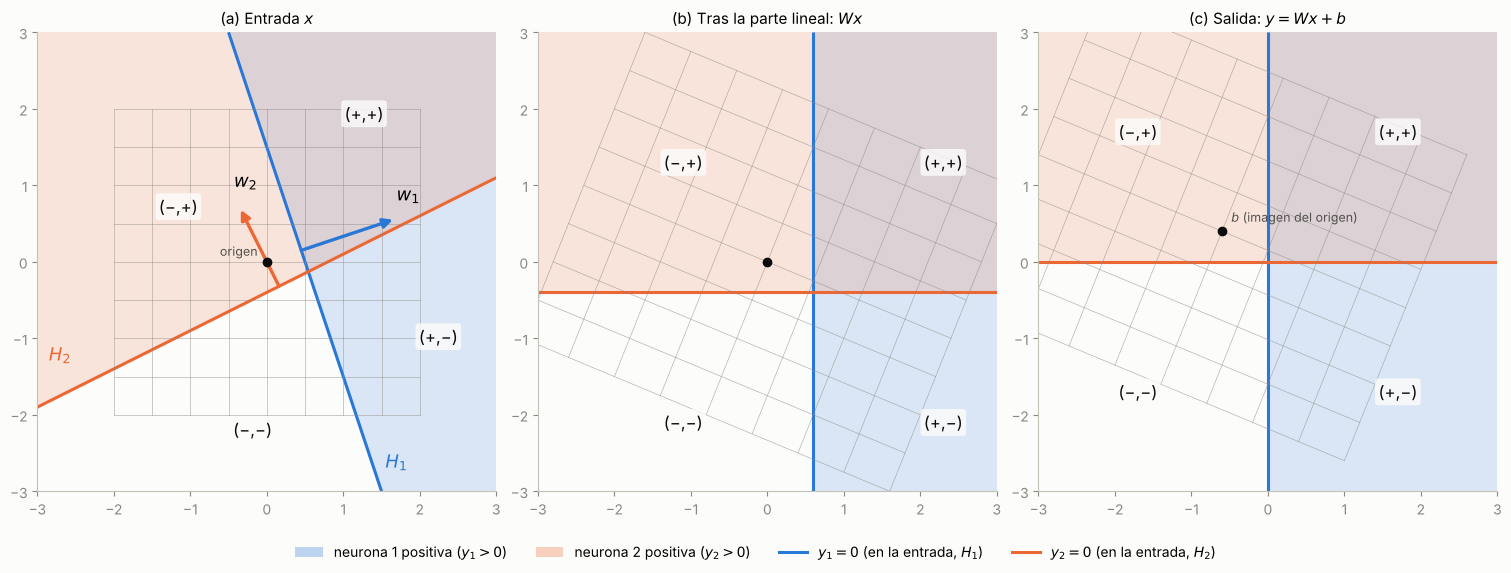

In [17]:
W_2d = np.array([[1.2, 0.4],
                 [-0.5, 1.0]])
b_2d = np.array([-0.6, 0.4])
W_2d_inv = np.linalg.inv(W_2d)

# Cada panel: (título, entrada -> coordenadas del panel, coordenadas del panel -> salidas y = (y1, y2)).
paneles = [
    (r"(a) Entrada $x$", lambda P: P, lambda Q: Q @ W_2d.T + b_2d),
    (r"(b) Tras la parte lineal: $Wx$", lambda P: P @ W_2d.T, lambda Q: Q + b_2d),
    (r"(c) Salida: $y = Wx + b$", lambda P: P @ W_2d.T + b_2d, lambda Q: Q),
]
etiquetas = {(1, 1): "(+,+)", (-1, 1): "(−,+)", (-1, -1): "(−,−)", (1, -1): "(+,−)"}

fig, axes = plt.subplots(1, 3, figsize=(15, 5.8), layout="constrained")
ver = 3.0
g = np.linspace(-ver, ver, 400)
G1, G2 = np.meshgrid(g, g)
Q = np.column_stack([G1.ravel(), G2.ravel()])
for ax, (titulo, a_panel, a_salida) in zip(axes, paneles):
    Ysal = a_salida(Q)
    Y1, Y2 = Ysal[:, 0].reshape(G1.shape), Ysal[:, 1].reshape(G1.shape)
    ax.contourf(G1, G2, Y1, levels=[0, np.inf], colors=[COL["azul"]], alpha=0.16)
    ax.contourf(G1, G2, Y2, levels=[0, np.inf], colors=[COL["naranja"]], alpha=0.16)
    ax.contour(G1, G2, Y1, levels=[0], colors=[COL["azul"]], linewidths=2.2)
    ax.contour(G1, G2, Y2, levels=[0], colors=[COL["naranja"]], linewidths=2.2)
    horizontales, verticales = cuadricula(lim=2.0, paso=0.5)
    for linea in horizontales + verticales:
        L = a_panel(linea)
        ax.plot(L[:, 0], L[:, 1], color=COL["tenue"], lw=0.5, alpha=0.6)
    o = a_panel(np.zeros((1, 2)))[0]
    ax.plot(*o, "o", color=COL["tinta"], ms=6, zorder=6)
    for (s1, s2), texto in etiquetas.items():
        y_rep = np.array([1.7 * s1, 1.7 * s2])                    # punto representativo de cada cuadrante
        pos = a_panel((W_2d_inv @ (y_rep - b_2d))[None, :])[0]   # su posición en este panel
        ax.text(*pos, texto, ha="center", va="center", fontsize=12, color=COL["tinta"],
                bbox=dict(boxstyle="round,pad=0.2", fc=COL["fondo"], ec="none", alpha=0.8))
    ax.set_xlim(-ver, ver); ax.set_ylim(-ver, ver); ax.set_aspect("equal"); ax.set_title(titulo)

ax = axes[0]                                                     # normales y nombres en la entrada
for i, color in [(0, COL["azul"]), (1, COL["naranja"])]:
    w_i, b_i = W_2d[i], b_2d[i]
    pie = -b_i * w_i / (w_i @ w_i)                               # punto de H_i más cercano al origen
    flecha(ax, pie + w_i, pie, color=color, lw=2.4)
    ax.text(*(pie + 1.08 * w_i + np.array([-0.05, 0.22])), f"$w_{i + 1}$", fontsize=13)
ax.text(1.55, -2.7, r"$H_1$", fontsize=13, color=COL["azul"])
ax.text(-2.85, -1.3, r"$H_2$", fontsize=13, color=COL["naranja"])
axes[0].text(-0.12, 0.04, "origen", fontsize=9, color=COL["tinta2"], ha="right", va="bottom")
axes[2].text(b_2d[0] + 0.12, b_2d[1] + 0.12, r"$b$ (imagen del origen)", fontsize=9, color=COL["tinta2"])

leyenda = [
    Patch(facecolor=COL["azul"], alpha=0.3, label=r"neurona 1 positiva ($y_1 > 0$)"),
    Patch(facecolor=COL["naranja"], alpha=0.3, label=r"neurona 2 positiva ($y_2 > 0$)"),
    Line2D([], [], color=COL["azul"], lw=2.2, label=r"$y_1 = 0$ (en la entrada, $H_1$)"),
    Line2D([], [], color=COL["naranja"], lw=2.2, label=r"$y_2 = 0$ (en la entrada, $H_2$)"),
]
fig.legend(handles=leyenda, loc="outside lower center", ncol=4)
plt.show()

### 3.7 Derivadas de la capa (un anticipo del entrenamiento)

Entrenar una red es ajustar $W$ y $b$ para minimizar una función de pérdida, y eso exige derivadas. La capa afín tiene las derivadas más simples posibles, y es un buen lugar para practicar la **comprobación de gradientes con diferencias finitas**, que usaremos siempre que implementemos derivadas a mano.

**Jacobiano respecto a la entrada.** El jacobiano $J_f(x) \in \mathbb{R}^{m\times n}$ de $f(x) = Wx + b$ es la matriz cuya entrada $(i, j)$ es la derivada parcial de $y_i$ respecto a $x_j$. Como $y_i = \sum_{k=1}^{n} W_{ik}x_k + b_i$, al derivar respecto a $x_j$ solo sobrevive el término $k = j$:
$$
\frac{\partial y_i}{\partial x_j} = W_{ij}
\qquad\Longrightarrow\qquad
J_f(x) = W \quad\text{para todo } x \in \mathbb{R}^n .
$$
El jacobiano es **constante**: la mejor aproximación lineal de una función afín es su propia parte lineal. En una red con no linealidades, el jacobiano cambiará de un punto a otro.

**Gradiente respecto a los parámetros.** Tomemos un objetivo $y^\star \in \mathbb{R}^m$ y la pérdida cuadrática
$$
L(W, b) = \frac{1}{2}\,\|Wx + b - y^\star\|^2 = \frac{1}{2}\sum_{i=1}^{m} \big(y_i - y^\star_i\big)^2 .
$$
Por la regla de la cadena, para cada entrada $W_{jk}$ de $W$:
$$
\frac{\partial L}{\partial W_{jk}} = \sum_{i=1}^{m} \big(y_i - y^\star_i\big)\, \frac{\partial y_i}{\partial W_{jk}} .
$$
Como $y_i = \sum_{l=1}^{n} W_{il}x_l + b_i$, el peso $W_{jk}$ solo interviene en la neurona $j$:
$$
\frac{\partial y_i}{\partial W_{jk}} = \delta_{ij}\, x_k ,
$$
donde $\delta_{ij}$ es la delta de Kronecker ($1$ si $i = j$, $0$ si no). Sustituyendo, solo sobrevive el término $i = j$:
$$
\frac{\partial L}{\partial W_{jk}} = \big(y_j - y^\star_j\big)\, x_k
\qquad\Longrightarrow\qquad
\nabla_W L = (y - y^\star)\, x^\top \in \mathbb{R}^{m\times n}.
$$
Para el sesgo la cuenta es la misma sin el factor $x_k$, porque
$$
\frac{\partial y_i}{\partial b_j} = \delta_{ij}
\qquad\Longrightarrow\qquad
\nabla_b L = y - y^\star \in \mathbb{R}^{m}.
$$
El producto $(y - y^\star)x^\top$ es un **producto exterior**: columna ($m\times 1$) por fila ($1\times n$) da una matriz $m \times n$. Observa la comprobación de dimensiones gratuita: **el gradiente respecto a un parámetro tiene siempre la misma forma que el parámetro**, como debe ser para poder dar el paso de descenso $W \leftarrow W - \eta\, \nabla_W L$, con tasa de aprendizaje $\eta > 0$.

**Diferencias finitas centradas.** Para $g : \mathbb{R} \to \mathbb{R}$ tres veces derivable con continuidad y $h > 0$, el teorema de Taylor con resto aplicado a $g(h)$ y $g(-h)$ da (los términos en $g(0)$ y $g''(0)$ se cancelan al restar; el último paso usa el teorema del valor intermedio para $g'''$)
$$
\frac{g(h) - g(-h)}{2h} = g'(0) + \frac{h^2}{6}\, g'''(\xi)
\qquad\text{para algún } \xi \in (-h, h).
$$
El error de truncamiento es de orden $h^2$, y es **exactamente cero** si $g'''$ es idénticamente nula. Nuestra pérdida, vista como función de un solo parámetro con los demás fijos, es un polinomio de grado 2, así que la diferencia centrada es exacta salvo por el redondeo de coma flotante. El error que veamos será puro redondeo, que *crece* al achicar $h$ (es del orden de $\varepsilon\,|L|\,h^{-1}$): lo comprobaremos variando $h$.

In [18]:
def perdida(W, b, x, y_obj):
    r = W @ x + b - y_obj
    return 0.5 * r @ r


def gradientes_analiticos(W, b, x, y_obj):
    """(∇_W L, ∇_b L) = ((y - y*) x^T, y - y*)."""
    r = W @ x + b - y_obj
    return np.outer(r, x), r


def gradiente_numerico(fun, P, h=1e-5):
    """Diferencias centradas: perturba cada entrada de P (en una copia) en +h y -h."""
    G = np.zeros_like(P)
    for idx in np.ndindex(P.shape):
        P_mas, P_menos = P.copy(), P.copy()
        P_mas[idx] += h
        P_menos[idx] -= h
        G[idx] = (fun(P_mas) - fun(P_menos)) / (2 * h)
    return G


def jacobiano_numerico(f, x, h=1e-5):
    """Columna j: (f(x + h e_j) - f(x - h e_j)) / (2h)."""
    columnas = []
    for j in range(x.shape[0]):
        e = np.zeros_like(x)
        e[j] = h
        columnas.append((f(x + e) - f(x - e)) / (2 * h))
    return np.column_stack(columnas)


m, n = 4, 3
W = rng.standard_normal((m, n)); b = rng.standard_normal(m)
x = rng.standard_normal(n);      y_obj = rng.standard_normal(m)

gW, gb = gradientes_analiticos(W, b, x, y_obj)
gW_num = gradiente_numerico(lambda W_: perdida(W_, b, x, y_obj), W)
gb_num = gradiente_numerico(lambda b_: perdida(W, b_, x, y_obj), b)
comprobar_forma("∇_W L", gW, W.shape)
comprobar_forma("∇_b L", gb, b.shape)
comprobar_cercania("∇_W L: fórmula (y - y*) x^T vs diferencias finitas", gW, gW_num, atol=1e-8)
comprobar_cercania("∇_b L: fórmula  y - y*      vs diferencias finitas", gb, gb_num, atol=1e-8)

J = jacobiano_numerico(lambda z: W @ z + b, x)
comprobar_forma("J_f(x)", J, (m, n))
comprobar_cercania("J_f(x) = W", J, W, atol=1e-8)

print("\nError de las diferencias centradas en ∇_W L según h (pérdida cuadrática: solo hay redondeo):")
for h in [1e-1, 1e-3, 1e-5, 1e-7, 1e-9]:
    G = gradiente_numerico(lambda W_: perdida(W_, b, x, y_obj), W, h=h)
    print(f"   h = {h:.0e}   error máximo = {np.max(np.abs(G - gW)):.1e}")

[ok] forma de ∇_W L = (4, 3)
[ok] forma de ∇_b L = (4,)
[ok] ∇_W L: fórmula (y - y*) x^T vs diferencias finitas  (error absoluto máximo = 2.3e-11)
[ok] ∇_b L: fórmula  y - y*      vs diferencias finitas  (error absoluto máximo = 2.6e-11)
[ok] forma de J_f(x) = (4, 3)
[ok] J_f(x) = W  (error absoluto máximo = 2.3e-11)

Error de las diferencias centradas en ∇_W L según h (pérdida cuadrática: solo hay redondeo):
   h = 1e-01   error máximo = 4.4e-15
   h = 1e-03   error máximo = 5.4e-13
   h = 1e-05   error máximo = 2.3e-11
   h = 1e-07   error máximo = 4.3e-09
   h = 1e-09   error máximo = 4.3e-07


La tabla confirma la teoría: incluso con $h = 10^{-1}$ el error es del orden del redondeo (no hay error de truncamiento en una función cuadrática), y al hacer $h$ más pequeño el error **aumenta**, porque restamos dos números casi iguales y dividimos por un $h$ diminuto. Moraleja práctica: "más pequeño" no siempre es mejor en diferencias finitas.

### 3.8 La versión con librería: PyTorch (opcional)

`torch.nn.Linear(in_features=n, out_features=m)` es exactamente nuestra capa afín. Comprobamos tres cosas: la convención de formas de sus pesos, que con nuestros $W$ y $b$ da la misma salida (para un ejemplo y para un lote), y que su diferenciación automática (*autograd*) produce los mismos gradientes que nuestra fórmula $(y - y^\star)\,x^\top$.

In [19]:
try:
    import torch
except ImportError:
    torch = None

if torch is None:
    print("PyTorch no está instalado: se omite esta comparación (se instala con `pip install torch`).")
else:
    capa = torch.nn.Linear(in_features=3, out_features=2, dtype=torch.float64)
    print("capa.weight.shape =", tuple(capa.weight.shape), " -> (out_features, in_features) = (m, n)")
    print("capa.bias.shape   =", tuple(capa.bias.shape))
    with torch.no_grad():                                   # copiamos W y b del ejemplo de 3.4
        capa.weight.copy_(torch.from_numpy(W_ej))
        capa.bias.copy_(torch.from_numpy(b_ej))

    y_torch = capa(torch.from_numpy(x_ej))
    comprobar_cercania("nn.Linear(x) = nuestra capa", y_torch.detach().numpy(), y_ej)
    Y_torch = capa(torch.from_numpy(X_lote))                # lote (N, 3) -> (N, 2), calcula X W^T + b
    comprobar_cercania("nn.Linear(X) = X W^T + b", Y_torch.detach().numpy(), Y_lote)

    y_obj_ej = np.array([0.5, 1.0])
    L_torch = 0.5 * ((capa(torch.from_numpy(x_ej)) - torch.from_numpy(y_obj_ej)) ** 2).sum()
    L_torch.backward()
    gW_ej, gb_ej = gradientes_analiticos(W_ej, b_ej, x_ej, y_obj_ej)
    comprobar_cercania("autograd ∇_W L = (y - y*) x^T", capa.weight.grad.numpy(), gW_ej)
    comprobar_cercania("autograd ∇_b L = y - y*", capa.bias.grad.numpy(), gb_ej)

capa.weight.shape = (2, 3)  -> (out_features, in_features) = (m, n)
capa.bias.shape   = (2,)
[ok] nn.Linear(x) = nuestra capa  (error absoluto máximo = 0.0e+00)
[ok] nn.Linear(X) = X W^T + b  (error absoluto máximo = 0.0e+00)
[ok] autograd ∇_W L = (y - y*) x^T  (error absoluto máximo = 0.0e+00)
[ok] autograd ∇_b L = y - y*  (error absoluto máximo = 0.0e+00)


## 4. ¿Por qué hace falta una no linealidad?

### 4.1 La pregunta

Si una capa es afín, ¿qué ganamos apilando dos? La intuición dice "más profundidad, más poder". Las matemáticas dicen que, si todas las capas son afines, **no ganamos nada**: la composición es otra función afín. En esta sección lo demostramos, lo comprobamos numéricamente, vemos un problema concreto (XOR) que ninguna pila de capas afines puede resolver, y vemos cómo una no linealidad lo arregla.

### 4.2 Primero: componer transformaciones lineales es multiplicar matrices

**Definición (producto de matrices).** Para $B \in \mathbb{R}^{p\times m}$ y $A \in \mathbb{R}^{m\times n}$, el producto $BA \in \mathbb{R}^{p \times n}$ tiene entradas
$$
(BA)_{ik} = \sum_{j=1}^{m} B_{ij}\, A_{jk},
\qquad i = 1, \dots, p,\quad k = 1, \dots, n.
$$
Regla de dimensiones: $(p\times m)\cdot(m \times n) = (p \times n)$.

Esta regla, que en un primer curso parece arbitraria, está **elegida** para que se cumpla lo siguiente.

**Teorema (componer es multiplicar).** Para todo $x \in \mathbb{R}^n$, $B(Ax) = (BA)x$.

*Demostración.* Para cada $i = 1, \dots, p$, intercambiando el orden de dos sumas finitas:
$$
\big(B(Ax)\big)_i
= \sum_{j=1}^{m} B_{ij}\,(Ax)_j
= \sum_{j=1}^{m} B_{ij} \sum_{k=1}^{n} A_{jk}\,x_k
= \sum_{k=1}^{n} \Big(\sum_{j=1}^{m} B_{ij}A_{jk}\Big) x_k
= \big((BA)x\big)_i . \qquad \blacksquare
$$

Así, "aplicar $A$ y luego $B$" es "aplicar la matriz $BA$" (ojo al orden: la que actúa primero queda a la derecha). Y como el orden de las transformaciones importa, el producto de matrices **no es conmutativo** en general.

In [20]:
def matmul_desde_cero(B, A):
    """Producto BA con el triple bucle de la definición."""
    p, m = B.shape
    m2, n = A.shape
    assert m == m2, f"dimensiones interiores incompatibles: {B.shape} por {A.shape}"
    C = np.zeros((p, n))
    for i in range(p):
        for k in range(n):
            for j in range(m):
                C[i, k] += B[i, j] * A[j, k]
    return C


B = rng.standard_normal((2, 4))
A = rng.standard_normal((4, 3))
x = rng.standard_normal(3)
comprobar_forma("BA", matmul_desde_cero(B, A), (2, 3))
comprobar_cercania("desde cero = B @ A", matmul_desde_cero(B, A), B @ A)
comprobar_cercania("B(Ax) = (BA)x", B @ (A @ x), (B @ A) @ x)

# No conmutatividad: rotar y luego escalar no es lo mismo que escalar y luego rotar.
R, S = galeria["Rotación de 30°"], galeria["Escalado"]
print("S R (rotar, luego escalar) =\n", S @ R)
print("R S (escalar, luego rotar) =\n", R @ S)
print("¿S R = R S?", np.allclose(S @ R, R @ S))

[ok] forma de BA = (2, 3)
[ok] desde cero = B @ A  (error absoluto máximo = 2.2e-16)
[ok] B(Ax) = (BA)x  (error absoluto máximo = 4.4e-16)
S R (rotar, luego escalar) =
 [[ 1.299 -0.75 ]
 [ 0.25   0.433]]
R S (escalar, luego rotar) =
 [[ 1.299 -0.25 ]
 [ 0.75   0.433]]
¿S R = R S? False


### 4.3 El teorema del colapso

**Teorema (dos capas afines son una capa afín).** Sean $f_1(x) = W_1 x + b_1$, con $W_1 \in \mathbb{R}^{h\times n}$ y $b_1 \in \mathbb{R}^h$, y $f_2(z) = W_2 z + b_2$, con $W_2 \in \mathbb{R}^{m\times h}$ y $b_2 \in \mathbb{R}^m$. Aquí $h$ (un entero positivo) es el ancho de la capa oculta y $z \in \mathbb{R}^h$ su salida. Entonces, para todo $x \in \mathbb{R}^n$,
$$
f_2\big(f_1(x)\big) = W x + b,
\qquad\text{con}\quad
W = W_2 W_1 \in \mathbb{R}^{m\times n},
\quad
b = W_2 b_1 + b_2 \in \mathbb{R}^m .
$$

*Demostración.* Sustituimos y usamos la linealidad del producto matriz-vector (teorema 1 de 2.3) y el teorema de 4.2:
$$
f_2\big(f_1(x)\big) = W_2\,(W_1 x + b_1) + b_2 = W_2 W_1\, x + W_2 b_1 + b_2 = \underbrace{(W_2 W_1)}_{W}\, x + \underbrace{(W_2 b_1 + b_2)}_{b} . \qquad \blacksquare
$$
Comprobación de dimensiones: $(m\times h)\cdot(h\times n) = (m \times n)$ para $W$, y $(m\times h)\cdot(h\times 1) + (m\times 1) = (m\times 1)$ para $b$.

**Corolario (cualquier profundidad).** La composición de $L$ capas afines $f_\ell(z) = W_\ell z + b_\ell$, con $\ell = 1, \dots, L$ y dimensiones compatibles, es afín:
$$
\big(f_L \circ \cdots \circ f_1\big)(x) = \big(W_L W_{L-1}\cdots W_1\big)\, x \;+\; \sum_{\ell=1}^{L} \big(W_L W_{L-1} \cdots W_{\ell+1}\big)\, b_\ell ,
$$
donde, para $\ell = L$, el producto vacío se interpreta como la matriz identidad.

*Demostración.* Por inducción sobre $L$. Para $L = 1$ es la definición. Si $g = f_{L-1}\circ\cdots\circ f_1$ es afín, $g(x) = Vx + c$, entonces $f_L \circ g$ es afín por el teorema, con matriz $W_L V$ y sesgo $W_L c + b_L$. Sustituyendo las expresiones de $V$ y $c$ que da la hipótesis de inducción se obtiene la fórmula explícita. $\blacksquare$

**Segunda demostración, con coordenadas homogéneas (la de la robótica).** Con las matrices aumentadas de 3.3, componer capas es multiplicar matrices (cada $0$ con la dimensión que corresponda):
$$
\widetilde{W}_2\, \widetilde{W}_1
= \begin{pmatrix} W_2 & b_2 \\ 0^\top & 1 \end{pmatrix}\begin{pmatrix} W_1 & b_1 \\ 0^\top & 1 \end{pmatrix}
= \begin{pmatrix} W_2 W_1 + b_2 0^\top & W_2 b_1 + b_2 \\ 0^\top W_1 + 0^\top & 0^\top b_1 + 1 \end{pmatrix}
= \begin{pmatrix} W_2 W_1 & W_2 b_1 + b_2 \\ 0^\top & 1 \end{pmatrix},
$$
que es la matriz aumentada de una sola capa afín, con los mismos $W$ y $b$ del teorema. Es exactamente lo que se hace en cinemática directa al encadenar las transformaciones homogéneas de los eslabones de un brazo robótico.

### 4.4 Verificación numérica del colapso

Construimos una red con **cinco** capas afines aleatorias, $\mathbb{R}^4 \to \mathbb{R}^{16} \to \mathbb{R}^{32} \to \mathbb{R}^{16} \to \mathbb{R}^{8} \to \mathbb{R}^3$, la colapsamos en una sola capa de $3 \times 4$ y comparamos las salidas en 1000 entradas aleatorias. Usamos error **relativo**, porque al multiplicar cinco matrices aleatorias las salidas pueden ser grandes.

In [21]:
def red_afin(capas, x):
    """Aplica una lista de capas afines [(W1, b1), (W2, b2), ...] en orden."""
    for W, b in capas:
        x = W @ x + b
    return x


def colapsar(capas):
    """(W, b) de la única capa afín equivalente, acumulando W <- W_l W y b <- W_l b + b_l."""
    n = capas[0][0].shape[1]
    W_total, b_total = np.eye(n), np.zeros(n)
    for W, b in capas:
        W_total, b_total = W @ W_total, W @ b_total + b
    return W_total, b_total


def aumentar(W, b):
    """Matriz homogénea [[W, b], [0^T, 1]]."""
    m, n = W.shape
    return np.block([[W, b[:, None]], [np.zeros((1, n)), np.ones((1, 1))]])


anchos = [4, 16, 32, 16, 8, 3]
capas = [(rng.standard_normal((anchos[l + 1], anchos[l])), rng.standard_normal(anchos[l + 1]))
         for l in range(len(anchos) - 1)]
for l, (W, b) in enumerate(capas, start=1):
    comprobar_forma(f"W_{l}", W, (anchos[l], anchos[l - 1]))

W_c, b_c = colapsar(capas)
comprobar_forma("W colapsada", W_c, (3, 4))
comprobar_forma("b colapsado", b_c, (3,))

X_prueba = rng.standard_normal((1000, 4))
salidas_red = np.array([red_afin(capas, x) for x in X_prueba])     # capa a capa, ejemplo a ejemplo
salidas_colapsada = X_prueba @ W_c.T + b_c                          # una sola capa, en lote
print(f"magnitud típica de las salidas: {np.abs(salidas_red).mean():.1f}")
comprobar_cercania("5 capas afines = 1 capa colapsada", salidas_red, salidas_colapsada, atol=1e-12, relativo=True)

W_tilde_total = np.eye(anchos[0] + 1)
for W, b in capas:
    W_tilde_total = aumentar(W, b) @ W_tilde_total
comprobar_forma("producto de matrices homogéneas", W_tilde_total, (4, 5))
comprobar_cercania("homogéneas: bloque W", W_tilde_total[:3, :4], W_c, atol=1e-12, relativo=True)
comprobar_cercania("homogéneas: bloque b", W_tilde_total[:3, 4], b_c, atol=1e-12, relativo=True)
comprobar_cercania("homogéneas: última fila (0, ..., 0, 1)", W_tilde_total[3], [0, 0, 0, 0, 1])

[ok] forma de W_1 = (16, 4)
[ok] forma de W_2 = (32, 16)
[ok] forma de W_3 = (16, 32)
[ok] forma de W_4 = (8, 16)
[ok] forma de W_5 = (3, 8)
[ok] forma de W colapsada = (3, 4)
[ok] forma de b colapsado = (3,)
magnitud típica de las salidas: 293.3
[ok] 5 capas afines = 1 capa colapsada  (error relativo máximo = 4.4e-16)
[ok] forma de producto de matrices homogéneas = (4, 5)
[ok] homogéneas: bloque W  (error relativo máximo = 3.1e-16)
[ok] homogéneas: bloque b  (error relativo máximo = 2.0e-16)
[ok] homogéneas: última fila (0, ..., 0, 1)  (error absoluto máximo = 0.0e+00)


### 4.5 Peor que inútil: el cuello de botella del rango

El colapso dice que apilar capas afines no aumenta lo que la red puede representar. Pero sí puede **reducirlo**. Recordemos que el **rango** de una matriz $M$, $\operatorname{rango}(M)$, es la dimensión de su imagen (equivalentemente, el número máximo de columnas linealmente independientes), y su **núcleo** $\ker(M)$ es el conjunto de vectores que envía a $0$.

**Teorema.** Para $W_1 \in \mathbb{R}^{h\times n}$ y $W_2 \in \mathbb{R}^{m\times h}$,
$$
\operatorname{rango}(W_2 W_1) \;\le\; \min\big(\operatorname{rango}(W_1),\ \operatorname{rango}(W_2)\big) \;\le\; \min(n,\ h,\ m).
$$

*Demostración.* (i) Todo vector de la forma $W_2 W_1 x$ es de la forma $W_2 z$ (con $z = W_1x$), así que la imagen de $W_2W_1$ está contenida en la de $W_2$ y, por tanto, $\operatorname{rango}(W_2W_1) \le \operatorname{rango}(W_2)$. (ii) Si $W_1 x = 0$, entonces $W_2W_1x = 0$: el núcleo de $W_1$ está contenido en el de $W_2W_1$. Por el teorema de la dimensión (rango-nulidad), $n = \operatorname{rango}(M) + \dim\ker(M)$ para cualquier matriz $M$ con $n$ columnas; luego
$$
\operatorname{rango}(W_2W_1) = n - \dim\ker(W_2W_1) \;\le\; n - \dim\ker(W_1) = \operatorname{rango}(W_1).
$$
La última desigualdad del enunciado se debe a que el rango de una matriz no supera ni su número de filas ni el de columnas. $\blacksquare$

**Consecuencia.** Una red lineal $\mathbb{R}^{10} \to \mathbb{R}^{10}$ con una capa oculta de ancho $h = 2$ equivale a una sola matriz de $10\times 10$, pero **de rango a lo sumo 2**: obliga a todo $\mathbb{R}^{10}$ a pasar por un plano. Una capa oculta estrecha no añade expresividad; la quita.

In [22]:
n, h, m = 10, 2, 10
W1 = rng.standard_normal((h, n))
W2 = rng.standard_normal((m, h))
W = W2 @ W1
comprobar_forma("W = W2 W1", W, (m, n))
print("rango(W1) =", np.linalg.matrix_rank(W1), "  rango(W2) =", np.linalg.matrix_rank(W2),
      "  rango(W2 W1) =", np.linalg.matrix_rank(W))
print("valores singulares de W2 W1:", ", ".join(f"{s:.1e}" for s in np.linalg.svd(W, compute_uv=False)))
print("en comparación, una matriz gaussiana de 10x10 tiene rango", np.linalg.matrix_rank(rng.standard_normal((10, 10))))

[ok] forma de W = W2 W1 = (10, 10)
rango(W1) = 2   rango(W2) = 2   rango(W2 W1) = 2
valores singulares de W2 W1: 1.9e+01, 6.0e+00, 1.9e-15, 5.6e-16, 4.2e-16, 4.0e-16, 2.1e-16, 4.3e-17, 2.9e-17, 8.7e-18
en comparación, una matriz gaussiana de 10x10 tiene rango 10


Los valores singulares (que estudiaremos con la SVD; `matrix_rank` cuenta cuántos superan una pequeña tolerancia) cuentan la misma historia: solo dos son distintos de cero, y el resto son del orden de $10^{-15}$, es decir, redondeo. La comparación final usa otro teorema que no demostramos aquí: una matriz con entradas gaussianas independientes es invertible con probabilidad $1$, porque el conjunto de matrices singulares tiene medida de Lebesgue cero.

**Un matiz importante.** Las redes lineales profundas se estudian en teoría a pesar del colapso: la clase de funciones que representan es la misma que la de una sola capa, pero la *dinámica del entrenamiento* por descenso de gradiente sí cambia con la profundidad (Saxe, McClelland y Ganguli, 2014). El colapso es una afirmación sobre **qué** se puede representar, no sobre **cómo** se aprende.

### 4.6 Un problema que ninguna pila de capas afines resuelve: XOR

El XOR ("o exclusivo") toma dos bits y devuelve $1$ si son distintos:

| $x_1$ | $x_2$ | XOR |
|:---:|:---:|:---:|
| 0 | 0 | 0 |
| 1 | 0 | 1 |
| 0 | 1 | 1 |
| 1 | 1 | 0 |

Buscamos una función que sea positiva en los puntos de clase $1$ y negativa en los de clase $0$; así basta mirar su signo para clasificar.

**Teorema (XOR no es linealmente separable).** No existen $w \in \mathbb{R}^2$ y $b_0 \in \mathbb{R}$ tales que la función afín $g(x) = w^\top x + b_0$ sea positiva en $(1,0)$ y $(0,1)$ y negativa en $(0,0)$ y $(1,1)$.

*Demostración.* Supongamos que existen. Sumando las dos condiciones de la clase $1$, y por otro lado las dos de la clase $0$:
$$
g(1,0) + g(0,1) = (w_1 + b_0) + (w_2 + b_0) = w_1 + w_2 + 2b_0 > 0,
$$
$$
g(0,0) + g(1,1) = b_0 + (w_1 + w_2 + b_0) = w_1 + w_2 + 2b_0 < 0 .
$$
La misma cantidad no puede ser a la vez positiva y negativa: contradicción. $\blacksquare$

Geométricamente: las dos diagonales del cuadrado tienen el mismo punto medio, $(0.5,\ 0.5)$, y una función afín conserva los puntos medios (es una combinación afín con $\lambda = 0.5$, sección 3.2), así que $g(0.5,\ 0.5)$ tendría que ser la media de dos números positivos y, a la vez, la media de dos negativos.

**Corolario.** Ninguna red formada solo por capas afines, de cualquier profundidad y anchura, con salida escalar seguida de un umbral, resuelve XOR: por el teorema del colapso, la red entera es una única función afín $g$.

**Verificación numérica.** Dos experimentos que *podrían* haber refutado el teorema (y no lo hacen): el mejor ajuste afín por mínimos cuadrados a las etiquetas, y 100 000 pares $(w, b_0)$ aleatorios.

In [23]:
X_xor = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
t_xor = np.array([0.0, 1.0, 1.0, 0.0])

# (a) Mejor función afín por mínimos cuadrados (columna de unos para el sesgo b0).
X_aum = np.column_stack([X_xor, np.ones(4)])
coef, *_ = np.linalg.lstsq(X_aum, t_xor, rcond=None)
w_mc, b0_mc = np.round(coef[:2], 12) + 0.0, coef[2]      # el "+ 0.0" convierte -0.0 en 0.0
print("(a) mejor w =", w_mc, "  mejor b0 =", round(b0_mc, 4))
print("    predicciones en los 4 puntos:", X_xor @ w_mc + b0_mc)

# (b) Búsqueda aleatoria: ¿algún (w, b0) separa las clases por el signo?
params = rng.uniform(-5, 5, size=(100_000, 3))
valores = X_xor @ params[:, :2].T + params[:, 2]            # (4, 100000)
signos_deseados = np.where(t_xor == 1, 1.0, -1.0)[:, None]
separan = np.all(np.sign(valores) == signos_deseados, axis=0)
print(f"(b) pares (w, b0) aleatorios que separan XOR: {separan.sum()} de {len(params)}")

(a) mejor w = [0. 0.]   mejor b0 = 0.5
    predicciones en los 4 puntos: [0.5 0.5 0.5 0.5]
(b) pares (w, b0) aleatorios que separan XOR: 0 de 100000


El mejor ajuste afín es $w = 0$, $b_0 = 0.5$: predice $0.5$ para todo. Es la manera que tiene una recta de decir "no lo sé".

### 4.7 La no linealidad: ReLU

**Definición (ReLU).** La función $\operatorname{ReLU} : \mathbb{R} \to \mathbb{R}$ es $\operatorname{ReLU}(z) = \max(0, z)$. Aplicada a un vector actúa **componente a componente**: escribimos $\sigma : \mathbb{R}^h \to \mathbb{R}^h$ con $\sigma(z)_i = \max(0, z_i)$.

La ReLU no es lineal: $\sigma(1) + \sigma(-1) = 1$, mientras que $\sigma(1 + (-1)) = \sigma(0) = 0$. Tampoco es afín, porque no conserva puntos medios:
$$
\sigma\Big(\frac{1 + (-1)}{2}\Big) = \sigma(0) = 0
\;\neq\;
\frac{1}{2} = \frac{\sigma(1) + \sigma(-1)}{2}.
$$
Una red de dos capas con una ReLU en medio es
$$
F(x) = W_2\, \sigma(W_1 x + b_1) + b_2 .
$$
Si repasas la demostración del colapso, el paso que se rompe es precisamente el que "metía" $W_2$ dentro del paréntesis: ahora entre $W_2$ y $W_1x + b_1$ hay una $\sigma$, y en general $\sigma(u + v) \neq \sigma(u) + \sigma(v)$.

**Una solución explícita de XOR.** Es el ejemplo clásico de la sección 6.1 de Goodfellow, Bengio y Courville, *Deep Learning* (2016). Con $h = 2$ neuronas ocultas:
$$
W_1 = \begin{pmatrix} 1 & 1 \\ 1 & 1 \end{pmatrix},
\quad
b_1 = \begin{pmatrix} 0 \\ -1 \end{pmatrix},
\quad
W_2 = \begin{pmatrix} 1 & -2 \end{pmatrix},
\quad
b_2 = 0 .
$$
Llamemos $s = x_1 + x_2$. La capa oculta produce las **activaciones** $a = \sigma(W_1 x + b_1) \in \mathbb{R}^2$, con $a_1 = \max(0, s)$ y $a_2 = \max(0, s - 1)$, y la salida es $F(x) = a_1 - 2a_2$:

| $x$ | $s = x_1 + x_2$ | $a_1 = \max(0, s)$ | $a_2 = \max(0, s - 1)$ | $F(x) = a_1 - 2a_2$ |
|:---:|:---:|:---:|:---:|:---:|
| $(0,0)$ | 0 | 0 | 0 | 0 |
| $(1,0)$ | 1 | 1 | 0 | 1 |
| $(0,1)$ | 1 | 1 | 0 | 1 |
| $(1,1)$ | 2 | 2 | 1 | 0 |

$F$ reproduce XOR **exactamente**. ¿Qué ha pasado? Como función de $s$,
$$
F = \max(0, s) - 2\max(0, s - 1) =
\begin{cases}
0 & \text{si } s \le 0, \\
s & \text{si } 0 \le s \le 1, \\
2 - s & \text{si } s \ge 1,
\end{cases}
$$
una "tienda de campaña" con el pico en $s = 1$ (en el tercer caso, $s - 2(s - 1) = 2 - s$). La segunda neurona se enciende a partir de $s = 1$ y **dobla** la función hacia abajo. Ninguna función afín puede subir y luego bajar; una suma de ReLUs, sí.

Hay una segunda lectura, en el espacio de las activaciones: la capa oculta envía los cuatro puntos a $a = (0,0)$, $(1,0)$, $(1,0)$ y $(2,1)$. Los dos puntos de clase $1$ caen en el mismo sitio, y ahora **una recta sí los separa** (por ejemplo, $a_1 - 2a_2 = 0.5$). La capa oculta ha cambiado la representación de los datos hasta hacer el problema linealmente separable. En este ejemplo eso es un hecho exacto; la idea general de que "las redes aprenden representaciones en las que el problema se vuelve fácil" es una intuición valiosa, pero una **heurística**, no un teorema.

In [24]:
def relu(z):
    return np.maximum(0.0, z)


def red_relu(X, W1, b1, W2, b2):
    """F(x) = W2 relu(W1 x + b1) + b2 sobre cada fila de X. Devuelve (salidas, activaciones ocultas)."""
    A = relu(X @ W1.T + b1)
    return A @ W2.T + b2, A


W1_xor = np.array([[1.0, 1.0], [1.0, 1.0]]); b1_xor = np.array([0.0, -1.0])
W2_xor = np.array([[1.0, -2.0]]);            b2_xor = np.array([0.0])
F_xor, A_xor = red_relu(X_xor, W1_xor, b1_xor, W2_xor, b2_xor)
comprobar_forma("activaciones ocultas", A_xor, (4, 2))
comprobar_forma("salida", F_xor, (4, 1))
print("activaciones ocultas a (una fila por punto):\n", A_xor)
print("F(x) =", F_xor.ravel(), "   XOR =", t_xor)
comprobar_cercania("la red ReLU calcula XOR exactamente", F_xor.ravel(), t_xor)

# F NO es afín: el mejor ajuste afín a F sobre una rejilla del plano deja un residuo claramente no nulo.
g1, g2 = np.meshgrid(np.linspace(-0.5, 1.5, 41), np.linspace(-0.5, 1.5, 41))
P = np.column_stack([g1.ravel(), g2.ravel()])
F_P = red_relu(P, W1_xor, b1_xor, W2_xor, b2_xor)[0].ravel()
P_aum = np.column_stack([P, np.ones(len(P))])
coef, *_ = np.linalg.lstsq(P_aum, F_P, rcond=None)
print(f"mejor ajuste afín a F en la rejilla: error cuadrático medio = {np.mean((F_P - P_aum @ coef) ** 2):.4f}"
      "  (sería 0 si F fuera afín)")

[ok] forma de activaciones ocultas = (4, 2)
[ok] forma de salida = (4, 1)
activaciones ocultas a (una fila por punto):
 [[0. 0.]
 [1. 0.]
 [1. 0.]
 [2. 1.]]
F(x) = [0. 1. 1. 0.]    XOR = [0. 1. 1. 0.]
[ok] la red ReLU calcula XOR exactamente  (error absoluto máximo = 0.0e+00)
mejor ajuste afín a F en la rejilla: error cuadrático medio = 0.1714  (sería 0 si F fuera afín)


### 4.8 Visualización: lo que la no linealidad le hace al espacio

**Primera figura: cuadrículas.** Usamos las mismas herramientas de la sección 2 con dos capas afines de $\mathbb{R}^2$ en $\mathbb{R}^2$:

- (a) Las dos capas aplicadas una tras otra.
- (b) La única capa colapsada $W = W_2W_1$, $b = W_2b_1 + b_2$: la figura es **idéntica** a la (a), como exige el teorema. Rectas a rectas, paralelas a paralelas.
- (c) Las **mismas** dos capas con una ReLU en medio. Ahora las rectas **se doblan** (allí donde una neurona oculta cruza su umbral) y regiones enteras del plano **se aplastan**: donde las dos neuronas ocultas son negativas, la ReLU las anula y toda esa región va a parar a un único punto, $b_2$; donde solo una es negativa, la región correspondiente se aplasta sobre una semirrecta. Ninguna función afín puede tratar de forma distinta a distintas regiones del plano.

Podemos describir la imagen de (c) con exactitud. Como $W_1$ es invertible, $W_1x + b_1$ recorre todo $\mathbb{R}^2$; la ReLU lo envía sobre el cuadrante cerrado $\lbrace a \in \mathbb{R}^2 : a_1 \ge 0,\ a_2 \ge 0 \rbrace$; y $W_2$ transforma ese cuadrante en el **cono** formado por las combinaciones con coeficientes no negativos de las dos columnas de $W_2$, que finalmente se traslada a $b_2$. Es la región en forma de cuña que se ve en la figura.

[ok] figura (a) = figura (b) en 1000 puntos  (error absoluto máximo = 8.9e-16)


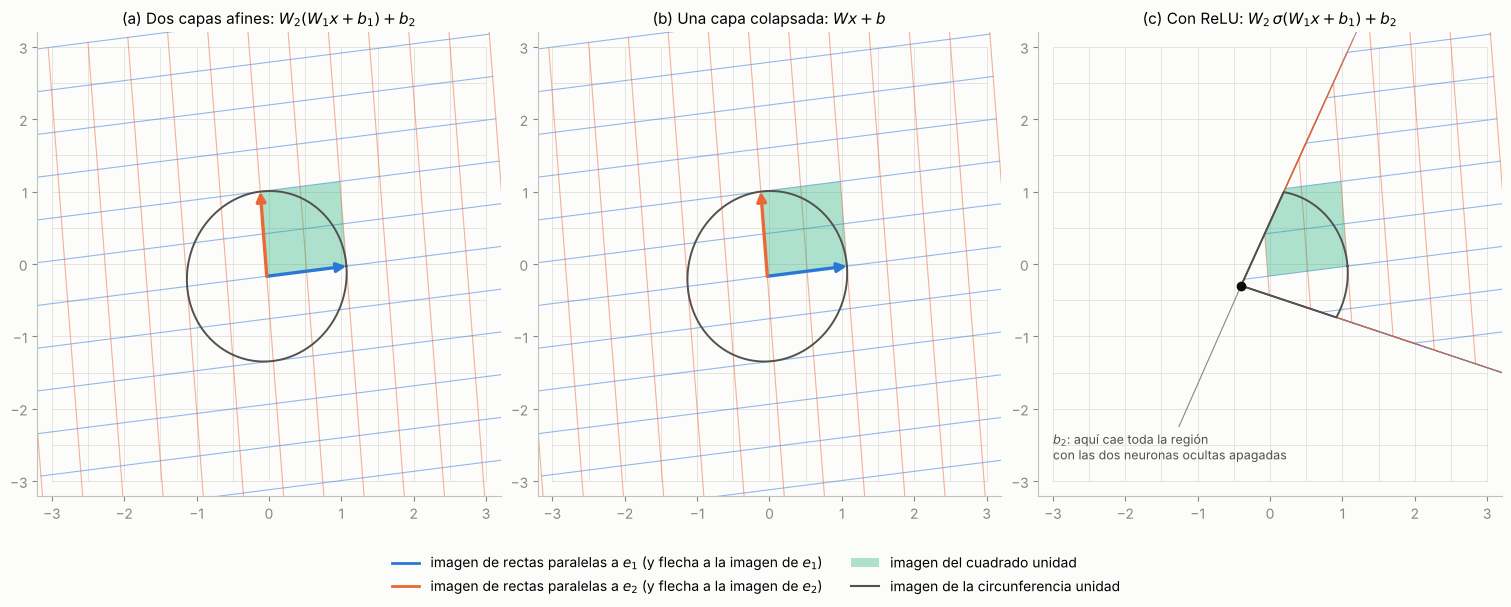

In [25]:
W1_v = np.array([[1.0, -0.6], [0.4, 0.9]]); b1_v = np.array([0.3, 0.2])
W2_v = np.array([[0.9, 0.5], [-0.3, 1.1]]); b2_v = np.array([-0.4, -0.3])
dos_capas = lambda P: (P @ W1_v.T + b1_v) @ W2_v.T + b2_v
W_col, b_col = W2_v @ W1_v, W2_v @ b1_v + b2_v
colapsada = lambda P: P @ W_col.T + b_col
con_relu = lambda P: relu(P @ W1_v.T + b1_v) @ W2_v.T + b2_v

P_prueba = rng.standard_normal((1000, 2))
comprobar_cercania("figura (a) = figura (b) en 1000 puntos", dos_capas(P_prueba), colapsada(P_prueba))

fig, axes = plt.subplots(1, 3, figsize=(15, 6.2), layout="constrained")
dibujar_transformacion(axes[0], dos_capas, r"(a) Dos capas afines: $W_2(W_1x + b_1) + b_2$", ver=3.2)
dibujar_transformacion(axes[1], colapsada, r"(b) Una capa colapsada: $Wx + b$", ver=3.2)
dibujar_transformacion(axes[2], con_relu, r"(c) Con ReLU: $W_2\,\sigma(W_1x + b_1) + b_2$", ver=3.2, flechas=False)
axes[2].plot(*b2_v, "o", color=COL["tinta"], ms=6, zorder=6)
axes[2].annotate(r"$b_2$: aquí cae toda la región" + "\n" + "con las dos neuronas ocultas apagadas",
                 xy=b2_v, xytext=(-3.0, -2.7), fontsize=9, color=COL["tinta2"],
                 arrowprops=dict(arrowstyle="-", color=COL["tenue"], lw=0.8))
leyenda = [
    Line2D([], [], color=COL["azul"], lw=2, label=r"imagen de rectas paralelas a $e_1$ (y flecha a la imagen de $e_1$)"),
    Line2D([], [], color=COL["naranja"], lw=2, label=r"imagen de rectas paralelas a $e_2$ (y flecha a la imagen de $e_2$)"),
    Patch(facecolor=COL["aqua"], alpha=0.35, label="imagen del cuadrado unidad"),
    Line2D([], [], color=COL["tinta2"], lw=1.5, label="imagen de la circunferencia unidad"),
]
fig.legend(handles=leyenda, loc="outside lower center", ncol=2)
plt.show()

**Segunda figura: XOR.** (a) En el espacio de entrada, la región donde $F(x) > 0.5$ (naranja, clase $1$) es una franja diagonal, $0.5 < x_1 + x_2 < 1.5$: exactamente la tienda de campaña de 4.7 cortada a media altura. Las líneas grises marcan dónde se enciende cada neurona oculta ($s = 0$ y $s = 1$). Ninguna recta podría dibujar una franja. (b) En el espacio de activaciones ocultas, **todo el plano de entrada** se convierte en una curva doblada (gris): como las dos filas de $W_1$ son iguales, la capa oculta solo "ve" $s$, y la ReLU dobla esa recta en $s = 1$. Sobre esa curva, una recta separa las dos clases.

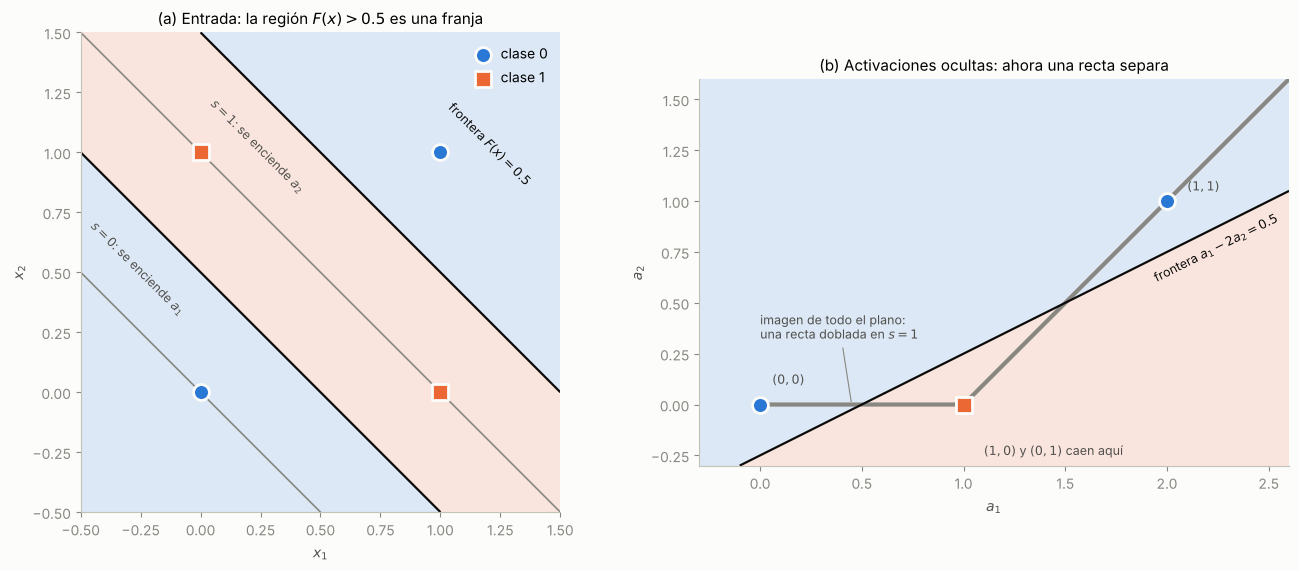

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.6), layout="constrained")

# --- (a) espacio de entrada ---------------------------------------------------
g = np.linspace(-0.5, 1.5, 401)
G1, G2 = np.meshgrid(g, g)
F_G = red_relu(np.column_stack([G1.ravel(), G2.ravel()]), W1_xor, b1_xor, W2_xor, b2_xor)[0].reshape(G1.shape)
ax1.contourf(G1, G2, F_G, levels=[-np.inf, 0.5, np.inf], colors=[COL["azul"], COL["naranja"]], alpha=0.15)
ax1.contour(G1, G2, F_G, levels=[0.5], colors=COL["tinta"], linewidths=1.6)
ax1.plot(g, -g, color=COL["tenue"], lw=1.2)
ax1.plot(g, 1 - g, color=COL["tenue"], lw=1.2)
ax1.text(-0.47, 0.32, r"$s = 0$: se enciende $a_1$", fontsize=9, color=COL["tinta2"], rotation=-45)
ax1.text(0.03, 0.83, r"$s = 1$: se enciende $a_2$", fontsize=9, color=COL["tinta2"], rotation=-45)
ax1.text(1.02, 0.86, r"frontera $F(x) = 0.5$", fontsize=9, color=COL["tinta"], rotation=-45)

# --- (b) espacio de activaciones ocultas -------------------------------------------
s_vals = np.linspace(-1.0, 2.6, 400)
curva = relu(np.column_stack([s_vals, s_vals - 1.0]))           # a(s) = (max(0, s), max(0, s - 1))
ga = np.linspace(-0.3, 2.6, 300)
GA1, GA2 = np.meshgrid(ga, np.linspace(-0.3, 1.6, 300))
salida_oculta = GA1 - 2 * GA2                                    # F en función de a (afín en a)
ax2.contourf(GA1, GA2, salida_oculta, levels=[-np.inf, 0.5, np.inf], colors=[COL["azul"], COL["naranja"]], alpha=0.15)
ax2.contour(GA1, GA2, salida_oculta, levels=[0.5], colors=COL["tinta"], linewidths=1.6)
ax2.plot(curva[:, 0], curva[:, 1], color=COL["tenue"], lw=3, zorder=1, solid_capstyle="round")
ax2.annotate("imagen de todo el plano:\nuna recta doblada en $s = 1$", xy=(0.45, 0.0), xytext=(0.0, 0.32),
             fontsize=9, color=COL["tinta2"], arrowprops=dict(arrowstyle="-", color=COL["tenue"], lw=0.8))
ax2.text(1.95, 0.6, r"frontera $a_1 - 2a_2 = 0.5$", fontsize=9, color=COL["tinta"],
         rotation=np.degrees(np.arctan(0.5)), rotation_mode="anchor")

# --- puntos de XOR en ambos espacios (marcador distinto por clase, además del color) -----
for clase, color, marcador in [(0, COL["azul"], "o"), (1, COL["naranja"], "s")]:
    idx = t_xor == clase
    for ax, puntos in [(ax1, X_xor), (ax2, A_xor)]:
        ax.scatter(puntos[idx, 0], puntos[idx, 1], s=130, color=color, marker=marcador,
                   edgecolor=COL["fondo"], linewidth=2, zorder=5, label=f"clase {clase}")
ax2.annotate(r"$(1,0)$ y $(0,1)$ caen aquí", xy=(1.0, 0.0), xytext=(1.1, -0.25), fontsize=9, color=COL["tinta2"])
ax2.annotate(r"$(1,1)$", xy=(2.0, 1.0), xytext=(2.1, 1.05), fontsize=9, color=COL["tinta2"])
ax2.annotate(r"$(0,0)$", xy=(0.0, 0.0), xytext=(0.06, 0.1), fontsize=9, color=COL["tinta2"])

ax1.set_xlim(-0.5, 1.5); ax1.set_ylim(-0.5, 1.5); ax1.set_aspect("equal")
ax1.set_xlabel(r"$x_1$"); ax1.set_ylabel(r"$x_2$")
ax1.set_title(r"(a) Entrada: la región $F(x) > 0.5$ es una franja")
ax2.set_xlim(-0.3, 2.6); ax2.set_ylim(-0.3, 1.6); ax2.set_aspect("equal")
ax2.set_xlabel(r"$a_1$"); ax2.set_ylabel(r"$a_2$")
ax2.set_title("(b) Activaciones ocultas: ahora una recta separa")
ax1.legend(loc="upper right", handletextpad=0.3)
plt.show()

### 4.9 ¿Qué no linealidad? Lo que es teorema, heurística y práctica

**Teorema (aproximación universal; Cybenko, 1989, y Hornik, Stinchcombe y White, 1989, para activaciones sigmoides; Leshno, Lin, Pinkus y Schocken, 1993, en general).** Sea $\sigma : \mathbb{R}\to\mathbb{R}$ continua. Las funciones de la forma
$$
x \;\mapsto\; \sum_{k=1}^{h} \alpha_k\, \sigma\big(w_k^\top x + b_k\big),
\qquad h \in \mathbb{N},\quad \alpha_k, b_k \in \mathbb{R},\quad w_k \in \mathbb{R}^n,
$$
es decir, redes con una capa oculta de ancho arbitrario, aproximan uniformemente cualquier función continua sobre cualquier compacto $K \subset \mathbb{R}^n$ **si y solo si $\sigma$ no es un polinomio**. **Demostración omitida** (usa herramientas de análisis funcional; una buena referencia es el artículo de revisión de Pinkus, 1999, en *Acta Numerica*).

**Por qué la excepción de los polinomios encaja con lo que demostramos.** Si $\sigma$ es un polinomio de grado $d$, cada término $\sigma(w_k^\top x + b_k)$ es un polinomio de grado a lo sumo $d$ en $x$, y una suma de ellos también. La red vive entonces en un espacio de dimensión finita de polinomios y no puede aproximarlo todo. El caso lineal, $d = 1$, es el extremo: solo obtenemos funciones afines, que es precisamente el teorema del colapso.

**Lo que el teorema NO dice.** No dice cuántas neuronas hacen falta (pueden ser muchísimas), ni cómo encontrar los pesos (entrenar es un problema de optimización no convexo, sin garantía general de llegar al óptimo), ni si lo aprendido generalizará a datos nuevos. Es un resultado de **existencia**.

**Práctica empírica.** La ReLU es la elección por defecto en muchas arquitecturas desde que Nair y Hinton (2010) y Glorot, Bordes y Bengio (2011) la popularizaron, porque **en experimentos** las redes profundas con ReLU entrenan más rápido que con sigmoides o con $\tanh$. La explicación habitual, que su derivada vale $1$ para $z > 0$ y por eso no "se satura" como la sigmoide (cuya derivada tiende a $0$ en las colas), es una **heurística** razonable, no un teorema. La ReLU también tiene problemas conocidos (neuronas "muertas" que quedan siempre en la zona $z < 0$ y dejan de aprender), y existen variantes (Leaky ReLU, GELU, etc.) cuya elección es, sobre todo, empírica.

**Sobre la profundidad.** Que las redes profundas funcionen mejor que las anchas y poco profundas es, en gran medida, una observación empírica. Existen teoremas para familias concretas de funciones que una red profunda representa con muchas menos neuronas que una poco profunda (por ejemplo, Telgarsky, 2016; Eldan y Shamir, 2016), pero no un resultado general que lo explique todo.

## 5. Resumen

La historia completa en una línea: **una neurona es un producto punto más un umbral; una capa es una transformación lineal más una traslación; y sin una no linealidad entre capas, cualquier profundidad colapsa en una sola capa.**

| Afirmación | Estatus | Cómo lo comprobamos |
|---|---|---|
| $x^\top y = \lVert x\rVert\,\lVert y\rVert\cos\theta$ en $\mathbb{R}^2$ | Teorema (1.4) | Fórmula del coseno frente a coordenadas polares |
| Ángulo en $\mathbb{R}^n$ | Definición, legítima gracias a Cauchy–Schwarz (teorema) | 10 000 pares aleatorios; caso de igualdad |
| La proyección ortogonal es el múltiplo más cercano | Teorema (1.5) | Residuo ortogonal; búsqueda en rejilla |
| Matrices y transformaciones lineales son lo mismo | Teoremas 1 y 2 (2.3) | Linealidad aleatoria; reconstrucción de una rotación |
| $\lvert\det A\rvert$ es el factor de área | Teorema (demostrado para el cuadrado; caso general omitido) | Fórmula del área de Gauss |
| $Wx + b$ es afín, y no lineal si $b \neq 0$ | Proposición (3.2) | $f(0) = b$; $f(u+v) = f(u) + f(v) - b$ |
| La salida de una neurona es una distancia con signo escalada | Proposición (3.6) | Pie de la perpendicular; 10 000 puntos de $H_1$ |
| $\nabla_W L = (y - y^\star)\,x^\top$ y $J_f = W$ | Derivación (3.7) | Diferencias finitas y autograd de PyTorch |
| Las capas afines apiladas colapsan en una | Teorema y corolario (4.3) | 5 capas frente a 1; coordenadas homogéneas |
| El rango del producto no supera el menor de los rangos | Teorema (4.5) | `matrix_rank` y valores singulares |
| XOR no es linealmente separable | Teorema (4.6) | Mínimos cuadrados; 100 000 pares aleatorios |
| Una red ReLU con 2 neuronas ocultas calcula XOR | Construcción explícita (4.7) | Evaluación exacta en los 4 puntos |
| Aproximación universal | Teorema (demostración omitida) | (no se verifica aquí) |
| La ReLU entrena bien en redes profundas | Práctica empírica, con una explicación heurística | (no se verifica aquí) |

### Para qué sirve todo esto más adelante

- **Robótica.** Las rotaciones de la galería ($\det = 1$, conservan longitudes) describen la orientación de un robot, y las transformaciones homogéneas $p \mapsto Rp + t$ tienen exactamente la forma de una capa; la cinemática directa de un brazo es un producto de matrices homogéneas, la misma cuenta del colapso. Pero, como función de los ángulos de las articulaciones, la cinemática es **no lineal** (aparecen senos y cosenos): por eso, para aprender modelos o políticas de control de un robot, hacen falta redes con no linealidades.
- **Aprendizaje automático.** Los siguientes pasos naturales son: generalizar las derivadas de 3.7 a una red con ReLU (retropropagación), entrenar desde cero una red pequeña que *aprenda* sola los pesos del XOR, y la SVD, que explica la elipse de la galería y el rango de 4.5.
- **Finanzas.** El rendimiento de una cartera es un producto punto $w^\top r$, y un modelo lineal de factores, $r = Bf + \epsilon$ (con cargas $B \in \mathbb{R}^{n\times k}$, factores $f \in \mathbb{R}^k$ y ruido $\epsilon \in \mathbb{R}^n$), es una capa afín más ruido.

### Ejercicios propuestos

1. **Pitágoras en $\mathbb{R}^n$.** Demuestra que $\|x + y\|^2 = \|x\|^2 + \|y\|^2$ si y solo si $x^\top y = 0$, y verifícalo numéricamente con vectores de $\mathbb{R}^{100}$.
2. **Composición en orden.** Construye, usando el teorema 2, la matriz que primero rota $90^\circ$ y luego refleja respecto a la diagonal $x_2 = x_1$ (calcula a mano adónde van $e_1$ y $e_2$). Compárala con los productos de las dos matrices en ambos órdenes. ¿Cuál coincide?
3. **Trampa del broadcasting en lote.** En `X_lote @ W_ej.T + b_columna`, ¿para qué valores de $N$ y $m$ NumPy da un resultado incorrecto *sin* lanzar ninguna excepción?
4. **Una activación polinomial.** Sustituye la ReLU por $\sigma(z) = z^2$. ¿Puedes resolver XOR con dos capas? (Pista: piensa en $(x_1 - x_2)^2$.) ¿Contradice esto el teorema de aproximación universal, que excluye los polinomios?
5. **Cuello de botella extremo.** Construye una red lineal de 10 capas $\mathbb{R}^{20} \to \cdots \to \mathbb{R}^{20}$ en la que una sola capa intermedia tenga ancho $1$. Predice el rango de la matriz colapsada y compruébalo.